# Профили вдоль орбиты: доля свистов и число молний

Ноутбук считает профиль одной полуорбиты: 30 равномерных по времени шагов от полюса к полюсу. На каждом шаге две величины — доля сэмплов со свистом и число молний WWLLN рядом с трассой. Сначала это спутник ka1. С пункта 7 к каждой его полуорбите подбирается полуорбита ka2.

**Слова, которые дальше используются без расшифровки**

- **Свист** — вистлер. В файлах предсказаний колонка `verdict`: 1 — свист отмечен на этом сэмпле, 0 — нет. Доля `verdict=1` на шаге — среднее таких сэмплов в окне 60 с вокруг шага.
- **ka1 и ka2** — два аппарата в одной орбитальной плоскости. ka2 пересекает экватор примерно на 50 минут раньше ka1 и на 12.7° восточнее. Расстояние между трассами такой пары около 1067 км и от пары к паре почти не меняется.
- **Полуорбита** — участок от одного разворота широты у полюса до следующего, около 50 минут. Полный виток — две полуорбиты, около 101 минуты.
- **Восходящая** полуорбита — широта вдоль шагов растёт, **нисходящая** — падает. У нисходящей тот же путь по широте разложен по оси шагов в обратную сторону, поэтому их рисуют отдельными графиками.
- **Молнии** — разряды WWLLN. На шаге берётся число разрядов в радиусе 1000 км за 500 с до момента шага.

**Данные и запуск**

Первая кодовая ячейка берёт пути через `wwlln_common.resolve_paths()`: каталог предсказаний `verdict` и каталог AE-файлов WWLLN. По умолчанию загружаются первые 30 суток, за которые есть ka1, начиная с 2025-01-20. Ячейки выполняются сверху вниз. `N_DAYS` сужает уже загруженное окно и к диску обращается, только если нужно больше суток, чем задано в `LOAD_DAYS`.

**Что в каком пункте**

1–2. Трек ka1 режется на полуорбиты, для каждой считается профиль из 30 шагов.

3–4. Профили, которые проходят Карибы или Океанию, накладываются друг на друга, отдельно ночь и день, отдельно восходящие (п.4) и нисходящие (п.4b). В заголовке панели `r` — корреляция Пирсона среднего профиля доли свистов и среднего профиля числа молний.

5–6. Три соседние полуорбиты одного направления, уже без фильтра региона: столбцы свистов и молний, полоса суша/вода и карта трассы. Пункты 6–6e — тот же рисунок на других датах.

7–9. Пара ka1 и ka2. Примеры п.7–9 идут над Тихим океаном и не заходят в зоны высокой концентрации свистов; Африка и Карибы собраны в п.8b. На каждом примере два графика: ближайшая пара и ещё одна полуорбита того же направления примерно на виток раньше или позже.

10. То же сопоставление сразу для всех чистых полуорбит. Первая ячейка — таблица пар и сходство профилей `verdict`. Вторая — шесть случайных пар.


In [1]:
%%time
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import wwlln_common as wc
importlib.reload(wc)

SC = 'ka1'
LOAD_DAYS = 30          # сколько суток грузим с диска (потолок, с запасом)
N_STEPS = 30            # точек на одну орбиту (полпериода)
VERDICT_WINDOW_S = 60   # окно усреднения доли verdict=1 вокруг шага
COUNT_RADIUS_KM = 1000.0
COUNT_WINDOW_S = 500     # окно назад (как в дозе) для количества молний перед шагом
MIN_TURN_LAT = 70.0     # разворот орбиты должен быть не ниже этой широты (иначе - шум)
MIN_TURN_GAP_S = 600    # минимальный интервал между развортами (дедупликация дребезга)
ORBIT_DUR_RANGE_S = (2500, 3500)  # "чистая" орбита - без пропусков данных

_paths_orb = wc.resolve_paths()
_orb_days_all = wc.analysis_days(_paths_orb['pred'], _paths_orb['ae'], (SC,))
if LOAD_DAYS is not None:
    _orb_days_all = _orb_days_all[:LOAD_DAYS]
print(f'загружено: {len(_orb_days_all)} суток ({_orb_days_all[0]} … {_orb_days_all[-1]})')

df_pred_orb_all = wc.load_predictions(_paths_orb['pred'], sc_list=(SC,), days=_orb_days_all)
df_pred_orb_all = df_pred_orb_all.sort_values('timestamp').reset_index(drop=True)
df_ae_orb_all = wc.load_ae(ae_dir=_paths_orb['ae'],
                            cache_path=_paths_orb['cache'] / 'AE_20250101_20251231.parquet',
                            days=_orb_days_all)
df_ae_orb_all = df_ae_orb_all.sort_values('datetime').reset_index(drop=True)
print(f'сэмплов {SC}: {len(df_pred_orb_all):,}, молний: {len(df_ae_orb_all):,}')

загружено: 30 суток (20250120 … 20250218)
ka1: 30 файлов из /Users/user/Downloads/wwlln/predictions/whistler_binary/ka1
AE из кэша: /Users/user/Downloads/wwlln/cache/AE_20250101_20251231.parquet
сэмплов ka1: 2,200,817, молний: 17,809,477
CPU times: user 10.4 s, sys: 11.2 s, total: 21.6 s
Wall time: 18.6 s


### Окно анализа

`LOAD_DAYS` в ячейке загрузки — сколько суток читать с диска. `N_DAYS` здесь берёт из них первые N и в расчёт дальше идут только они. Пока `N_DAYS` не больше `LOAD_DAYS`, достаточно перезапустить эту ячейку и всё, что ниже неё.


In [2]:
N_DAYS = 30  # <= LOAD_DAYS; можно менять и перезапускать только эту ячейку и ниже

_orb_days = _orb_days_all[:N_DAYS] if N_DAYS is not None else _orb_days_all
_cutoff = pd.Timestamp(_orb_days[-1]) + pd.Timedelta(days=1)

df_pred_orb = df_pred_orb_all[df_pred_orb_all['timestamp'] < _cutoff].reset_index(drop=True)
df_ae_orb = df_ae_orb_all[df_ae_orb_all['datetime'] < _cutoff].reset_index(drop=True)
print(f'период анализа: {len(_orb_days)} суток ({_orb_days[0]} … {_orb_days[-1]})')
print(f'сэмплов {SC}: {len(df_pred_orb):,}, молний: {len(df_ae_orb):,}')

период анализа: 30 суток (20250120 … 20250218)
сэмплов ka1: 2,200,817, молний: 17,809,477


## 1. Нарезка трека на полуорбиты

Разворот — точка, где широта перестаёт расти и начинает падать, или наоборот. Он ищется по смене знака производной сглаженной широты: сглаживание убирает дребезг знака в момент, когда широта у полюса почти стоит. Разворот принимается, если он не ниже `MIN_TURN_LAT` (70°) и отстоит от предыдущего не меньше чем на `MIN_TURN_GAP_S` (600 с).

Дальше в профили попадают только «чистые» промежутки между соседними разворотами: длительность внутри `ORBIT_DUR_RANGE_S` (2500–3500 с). Более длинный промежуток — дыра в телеметрии, а не одна полуорбита.


In [3]:
lat_all = df_pred_orb['geo_lat'].to_numpy(dtype=np.float64)
lon_all = df_pred_orb['geo_lon'].to_numpy(dtype=np.float64)
verdict_all = df_pred_orb['verdict'].to_numpy(dtype=np.int8)
t_all = df_pred_orb['timestamp'].values.astype('datetime64[s]').astype(np.int64)

_dt = np.diff(t_all)
_data_gap = np.concatenate([[False], _dt > 5])  # разрыв в самих данных (не разворот)

_lat_smooth = np.convolve(lat_all, np.ones(5) / 5, mode='same')
_dlat = np.diff(_lat_smooth)
_sign = np.sign(_dlat)
_sign[_sign == 0] = 1
_turn = np.concatenate([[False], (_sign[1:] != _sign[:-1])])
# _turn[m]=True уже означает экстремум РОВНО в исходном массиве по индексу m (проверено
# на синтетике) - без сдвига. Раньше здесь стояло "+ 1", что указывало на сэмпл на 1 позже
# настоящего разворота. Сдвиг на один сэмпл готовые профили почти не менял,
# но индекс был неверным.
turn_idx = np.where(_turn)[0]
turn_idx = turn_idx[~_data_gap[turn_idx]]
turn_idx = turn_idx[np.abs(_lat_smooth[turn_idx]) >= MIN_TURN_LAT]

_keep = [turn_idx[0]]
for _idx in turn_idx[1:]:
    if t_all[_idx] - t_all[_keep[-1]] >= MIN_TURN_GAP_S:
        _keep.append(_idx)
turn_idx = np.array(_keep)

_intervals = np.diff(t_all[turn_idx])
_clean_share = np.mean((_intervals >= ORBIT_DUR_RANGE_S[0]) & (_intervals <= ORBIT_DUR_RANGE_S[1]))
print(f'точек разворота: {len(turn_idx)}, "чистых" интервалов (один настоящий полупериод): {100*_clean_share:.1f}%')
print(f'медианная длительность полуорбиты: {np.median(_intervals):.0f} с')


точек разворота: 780, "чистых" интервалов (один настоящий полупериод): 96.7%
медианная длительность полуорбиты: 3038 с


## 2. Профиль одной полуорбиты

На каждой чистой полуорбите ставится `N_STEPS` = 30 точек, равномерно по времени. Координаты шага — ближайший реальный сэмпл. Доля `verdict=1` — среднее сэмплов в окне `VERDICT_WINDOW_S` (60 с) вокруг шага. Число молний — сколько разрядов WWLLN попало в радиус `COUNT_RADIUS_KM` (1000 км) за `COUNT_WINDOW_S` (500 с) до момента шага. Окно смотрит только назад: шаг не должен зависеть от молний, которые к этому моменту ещё не произошли. Ночь на шаге — солнечный зенитный угол больше `wc.NIGHT_SZA_DEG` (98°).

На выходе словарь: время, широта, долгота, доля `verdict`, число молний, признак ночи.


In [4]:
R_EARTH_KM = 6371.2

ae_t = df_ae_orb['datetime'].values.astype('datetime64[s]').astype(np.int64)
ae_lat_r = np.radians(df_ae_orb['lat'].to_numpy(dtype=np.float64))
ae_lon_r = np.radians(df_ae_orb['lon'].to_numpy(dtype=np.float64))


def lightning_count(step_lat, step_lon, step_t):
    """Сколько разрядов WWLLN попало в радиус COUNT_RADIUS_KM за последние
    COUNT_WINDOW_S секунд перед шагом. Окно только назад, как доза в
    wwlln_reader_shape.ipynb: шаг не видит молний, которые ещё не произошли."""
    n = len(step_lat)
    out = np.zeros(n, dtype=np.int32)
    for k in range(n):
        if not np.isfinite(step_lat[k]):
            continue
        i_lo = np.searchsorted(ae_t, step_t[k] - COUNT_WINDOW_S, side='left')
        i_hi = np.searchsorted(ae_t, step_t[k], side='right')
        if i_hi <= i_lo:
            continue
        lat2, lon2 = ae_lat_r[i_lo:i_hi], ae_lon_r[i_lo:i_hi]
        s_lat, s_lon = np.radians(step_lat[k]), np.radians(step_lon[k])
        dlat, dlon = lat2 - s_lat, lon2 - s_lon
        a = np.sin(dlat / 2) ** 2 + np.cos(s_lat) * np.cos(lat2) * np.sin(dlon / 2) ** 2
        dist = 2 * R_EARTH_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        out[k] = np.sum(dist <= COUNT_RADIUS_KM)
    return out


def build_orbit_profile(i0, i1):
    """Профиль одной орбиты между индексами разворота i0 и i1 (соседние). None, если
    интервал нестандартной длины (пропуск данных внутри)."""
    t0, t1 = t_all[i0], t_all[i1]
    if not (ORBIT_DUR_RANGE_S[0] <= (t1 - t0) <= ORBIT_DUR_RANGE_S[1]):
        return None
    step_times = np.linspace(t0, t1, N_STEPS)
    seg = (t_all >= t0) & (t_all <= t1)
    seg_t, seg_lat, seg_lon, seg_v = t_all[seg], lat_all[seg], lon_all[seg], verdict_all[seg]

    p_lat = np.full(N_STEPS, np.nan)
    p_lon = np.full(N_STEPS, np.nan)
    p_verdict = np.full(N_STEPS, np.nan)
    for k, st in enumerate(step_times):
        j = np.argmin(np.abs(seg_t - st))
        p_lat[k] = seg_lat[j]
        p_lon[k] = seg_lon[j]
        win = np.abs(seg_t - st) <= VERDICT_WINDOW_S
        if win.any():
            p_verdict[k] = seg_v[win].mean()

    p_count = lightning_count(p_lat, p_lon, step_times)
    p_sza = wc.solar_zenith_deg(step_times.astype('datetime64[s]'), p_lat, p_lon)
    p_night = p_sza > wc.NIGHT_SZA_DEG
    return {'t': step_times, 'lat': p_lat, 'lon': p_lon, 'verdict': p_verdict,
            'count': p_count, 'night': p_night}


## 3. Какие полуорбиты проходят регион, и ночь это или день

Профиль из п.2 считается один раз на полуорбиту. Регион — прямоугольник. Полуорбита в него попадает, если внутри прямоугольника лежит хотя бы один шаг.

Два прямоугольника в ячейке ниже:

- Карибы / С. Америка: `0…25°N`, `−90…−60°E`;
- Океания: `−20…5°N`, `110…150°E`.

Ночь и день считаются по шагам внутри прямоугольника, а не по всей полуорбите: за пролёт от полюса к полюсу освещённость вдоль трассы меняется. Полуорбита идёт в «ночь», если ночными оказались больше половины её шагов внутри региона.


In [5]:
%%time
REGIONS = {
    'Карибы / С.Америка': {'lat': (0, 25), 'lon': (-90, -60)},
    'Океания': {'lat': (-20, 5), 'lon': (110, 150)},
}

all_profiles = []
for i in range(len(turn_idx) - 1):
    prof = build_orbit_profile(turn_idx[i], turn_idx[i + 1])
    if prof is not None:
        all_profiles.append(prof)
print(f'построено профилей (все "чистые" орбиты за период): {len(all_profiles)}')

# ночь/день определяется по шагам ВНУТРИ региона (большинство голосов), а не по всей
# орбите целиком - т.к. за один пролёт (полюс -> полюс) освещённость вдоль орбиты меняется
region_profiles = {}
for reg_name, reg in REGIONS.items():
    night_list, day_list = [], []
    for p in all_profiles:
        in_reg = (
            (p['lat'] >= reg['lat'][0]) & (p['lat'] < reg['lat'][1]) &
            (p['lon'] >= reg['lon'][0]) & (p['lon'] < reg['lon'][1])
        )
        if not in_reg.any():
            continue
        is_night = p['night'][in_reg].mean() >= 0.5
        (night_list if is_night else day_list).append(p)
    region_profiles[reg_name] = {'ночь': night_list, 'день': day_list}
    print(f'{reg_name}: ночь={len(night_list)} орбит, день={len(day_list)} орбит')

построено профилей (все "чистые" орбиты за период): 753
Карибы / С.Америка: ночь=35 орбит, день=34 орбит
Океания: ночь=43 орбит, день=45 орбит
CPU times: user 7min 27s, sys: 9min, total: 16min 28s
Wall time: 16min 42s


## 4. Наложение профилей: восходящие, по региону и ночь/день

На одной панели только восходящие полуорбиты (широта от начала к концу растёт). Нисходящие — в п.4b: у них ось шагов разворачивает широту в обратную сторону, и на общем рисунке пучок рассыпается.

Жёлтые столбцы — доля `verdict=1`, синие — число молний. Каждая полуорбита поделена на свой максимум, поэтому высота показывает форму вдоль орбиты. Полупрозрачные столбцы наложены друг на друга: где пролёты похожи, цвет гуще. Средняя кривая на график не выводится. По ней считается `r` в заголовке — корреляция Пирсона среднего профиля свистов и среднего профиля молний на 30 шагах.

Строки панели — ночь и день, столбцы — два региона из п.3.


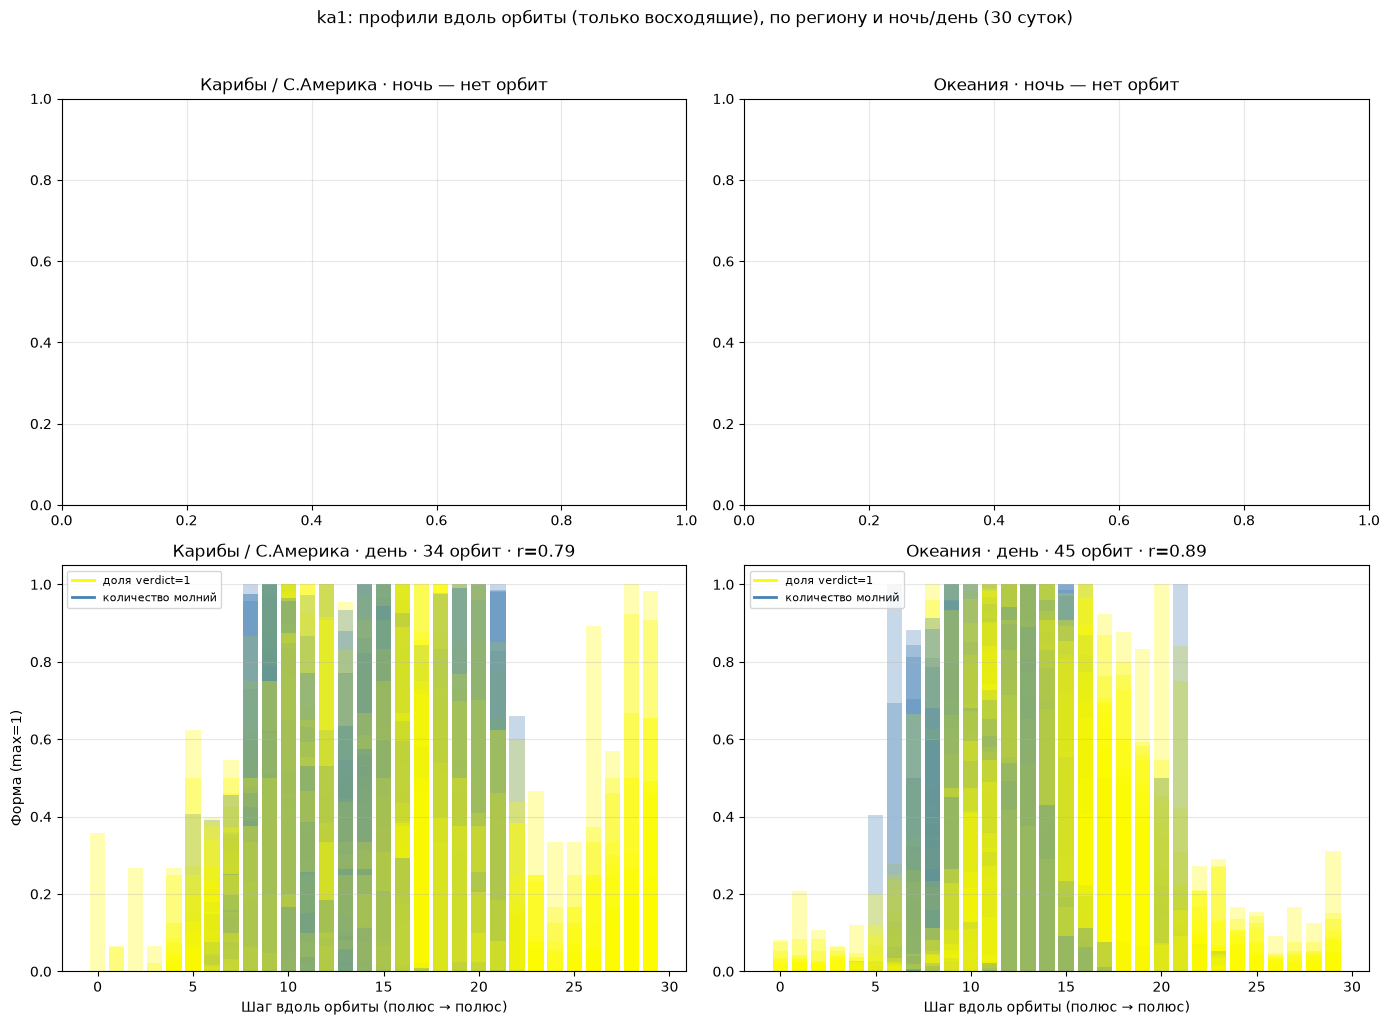

In [6]:
def _maxn(x):
    x = np.asarray(x, dtype=np.float64)
    m = np.nanmax(x) if np.isfinite(x).any() else np.nan
    if not np.isfinite(m) or m <= 0:
        return np.full_like(x, np.nan)
    return x / m


steps = np.arange(N_STEPS)
night_labels = ['ночь', 'день']
_legend_handles = [
    plt.Line2D([], [], color='#fcfb00', lw=2, label='доля verdict=1'),
    plt.Line2D([], [], color='steelblue', lw=2, label='количество молний'),
]
fig, axes = plt.subplots(len(night_labels), len(region_profiles),
                          figsize=(7 * len(region_profiles), 5 * len(night_labels)), squeeze=False)

for row, night_lab in enumerate(night_labels):
    for col, (reg_name, groups) in enumerate(region_profiles.items()):
        ax = axes[row, col]
        # только восходящие орбиты (широта в начале < широта в конце) - нисходящие
        # исключены, т.к. у них противоположная зеркальная развёртка по широте вдоль
        # оси шагов, и на одном рисунке с восходящими пучок рассыпается
        profs = [p for p in groups[night_lab] if p['lat'][0] < p['lat'][-1]]
        if not profs:
            ax.set_title(f'{reg_name} · {night_lab} — нет орбит')
            ax.grid(alpha=0.3)
            continue
        # bar chart: десятки орбит - раздвигать бары по каждой орбите нечитаемо,
        # поэтому те же полупрозрачные бары друг на друге (alpha), как раньше были линии
        for p in profs:
            ax.bar(steps, _maxn(p['verdict']), width=0.8, color='#fcfb00', alpha=0.3)
            ax.bar(steps, _maxn(p['count']), width=0.8, color='steelblue', alpha=0.3)

        # среднее не рисуется на графике, но по нему по-прежнему считается корреляция в заголовке
        mean_v = _maxn(np.nanmean([_maxn(p['verdict']) for p in profs], axis=0))
        mean_d = _maxn(np.nanmean([_maxn(p['count']) for p in profs], axis=0))
        mask = np.isfinite(mean_v) & np.isfinite(mean_d)
        r = np.corrcoef(mean_v[mask], mean_d[mask])[0, 1] if mask.sum() > 2 else np.nan

        ax.set_title(f'{reg_name} · {night_lab} · {len(profs)} орбит · r={r:.2f}')
        ax.set_xlabel('Шаг вдоль орбиты (полюс → полюс)')
        if col == 0:
            ax.set_ylabel('Форма (max=1)')
        ax.legend(handles=_legend_handles, fontsize=8)
        ax.grid(alpha=0.3, axis='y')

fig.suptitle(f'{SC}: профили вдоль орбиты (только восходящие), по региону и ночь/день ({len(_orb_days)} суток)', y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)


## 4b. То же наложение для нисходящих

Тот же рисунок, что в п.4: строки — ночь и день, столбцы — Карибы и Океания, `r` в заголовке считается так же. В выборку входят полуорбиты, у которых широта от начала к концу падает.


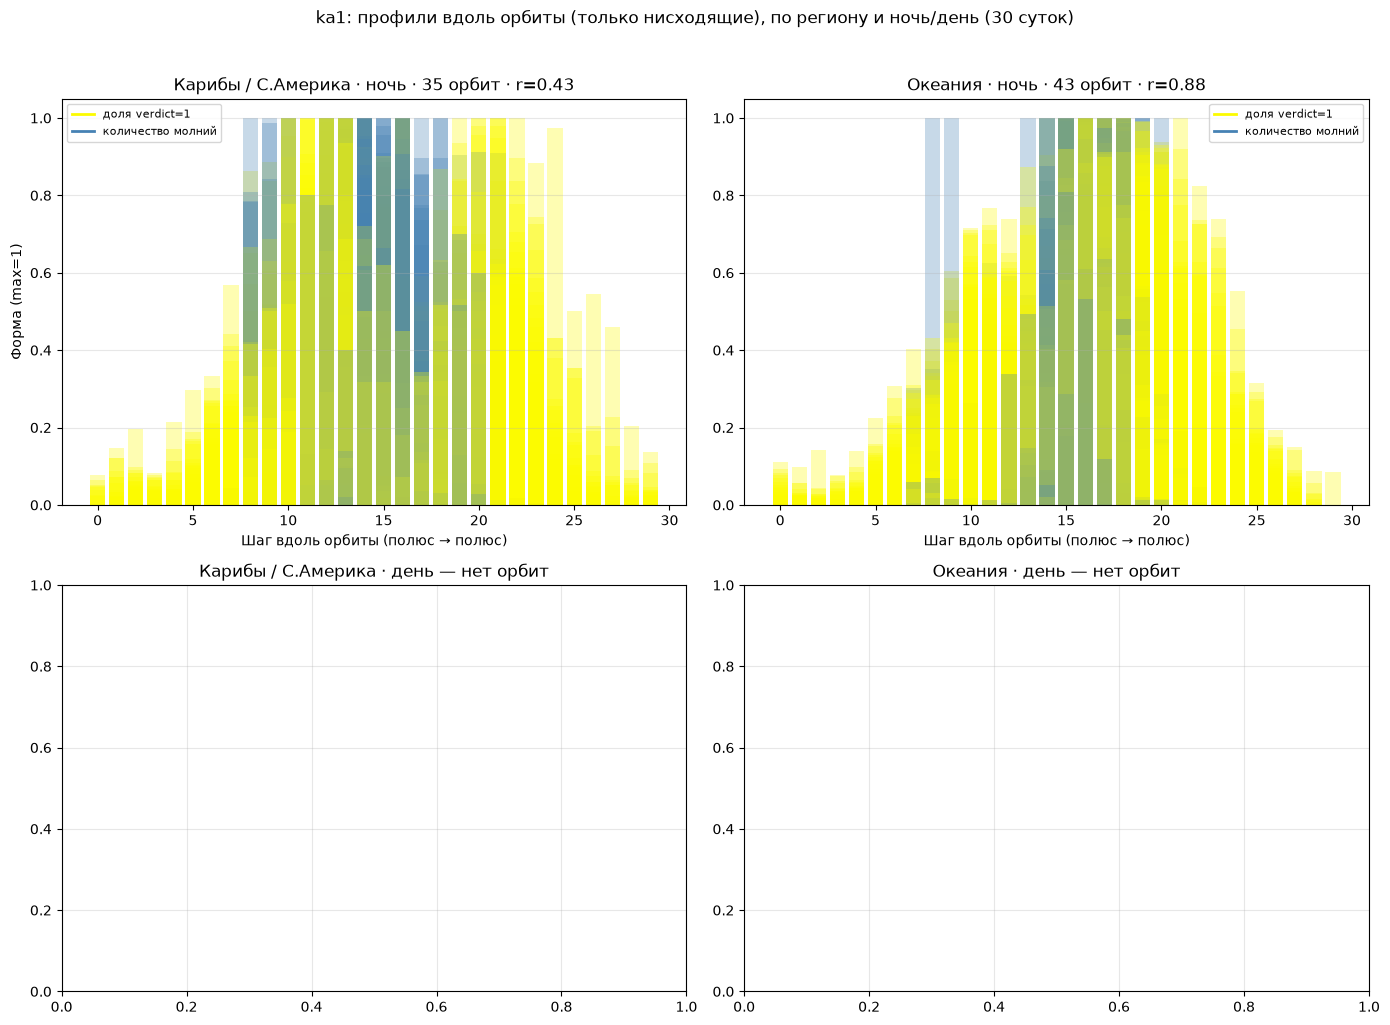

In [7]:
fig, axes = plt.subplots(len(night_labels), len(region_profiles),
                          figsize=(7 * len(region_profiles), 5 * len(night_labels)), squeeze=False)

for row, night_lab in enumerate(night_labels):
    for col, (reg_name, groups) in enumerate(region_profiles.items()):
        ax = axes[row, col]
        # только нисходящие орбиты (широта в начале > широта в конце) - зеркальное
        # условие по сравнению с ячейкой 11
        profs = [p for p in groups[night_lab] if p['lat'][0] > p['lat'][-1]]
        if not profs:
            ax.set_title(f'{reg_name} · {night_lab} — нет орбит')
            ax.grid(alpha=0.3)
            continue
        for p in profs:
            ax.bar(steps, _maxn(p['verdict']), width=0.8, color='#fcfb00', alpha=0.3)
            ax.bar(steps, _maxn(p['count']), width=0.8, color='steelblue', alpha=0.3)

        mean_v = _maxn(np.nanmean([_maxn(p['verdict']) for p in profs], axis=0))
        mean_d = _maxn(np.nanmean([_maxn(p['count']) for p in profs], axis=0))
        mask = np.isfinite(mean_v) & np.isfinite(mean_d)
        r = np.corrcoef(mean_v[mask], mean_d[mask])[0, 1] if mask.sum() > 2 else np.nan

        ax.set_title(f'{reg_name} · {night_lab} · {len(profs)} орбит · r={r:.2f}')
        ax.set_xlabel('Шаг вдоль орбиты (полюс → полюс)')
        if col == 0:
            ax.set_ylabel('Форма (max=1)')
        ax.legend(handles=_legend_handles, fontsize=8)
        ax.grid(alpha=0.3, axis='y')

fig.suptitle(f'{SC}: профили вдоль орбиты (только нисходящие), по региону и ночь/день ({len(_orb_days)} суток)', y=1.02)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. Три соседние восходящие полуорбиты

Здесь нет фильтра региона. Берутся три восходящие полуорбиты подряд. В списке `all_profiles` восходящие и нисходящие чередуются: это половины одного витка, и лежат они на противоположных долготах. Поэтому сначала оставляем только восходящие, и уже из них берём три подряд. Шаг между ними — полный виток (~101 мин), а не полвитка.

`START_IDX` — номер в списке восходящих, не в `all_profiles` целиком. Ячейка ниже начинает с нуля.

На каждую полуорбиту три части: жёлтым — доля свистов, синим — число молний (снова каждая кривая к своему максимуму; подпись «не плотность» значит, что синие столбцы — число разрядов в радиусе 1000 км), под осью — полоса суша/вода (зелёный — суша, голубой — вода, серый — нет координат), снизу — карта трассы от полюса к полюсу. Рядом общий график тех же трёх полуорбит и таблица времени пролёта и долгот.

Функции рисунка лежат в `orbit_profile_plots.py`.


проверка соседства: чисто, все 3 восходящих орбит идут подряд (шаг ~6077с = 101 мин, полный виток)


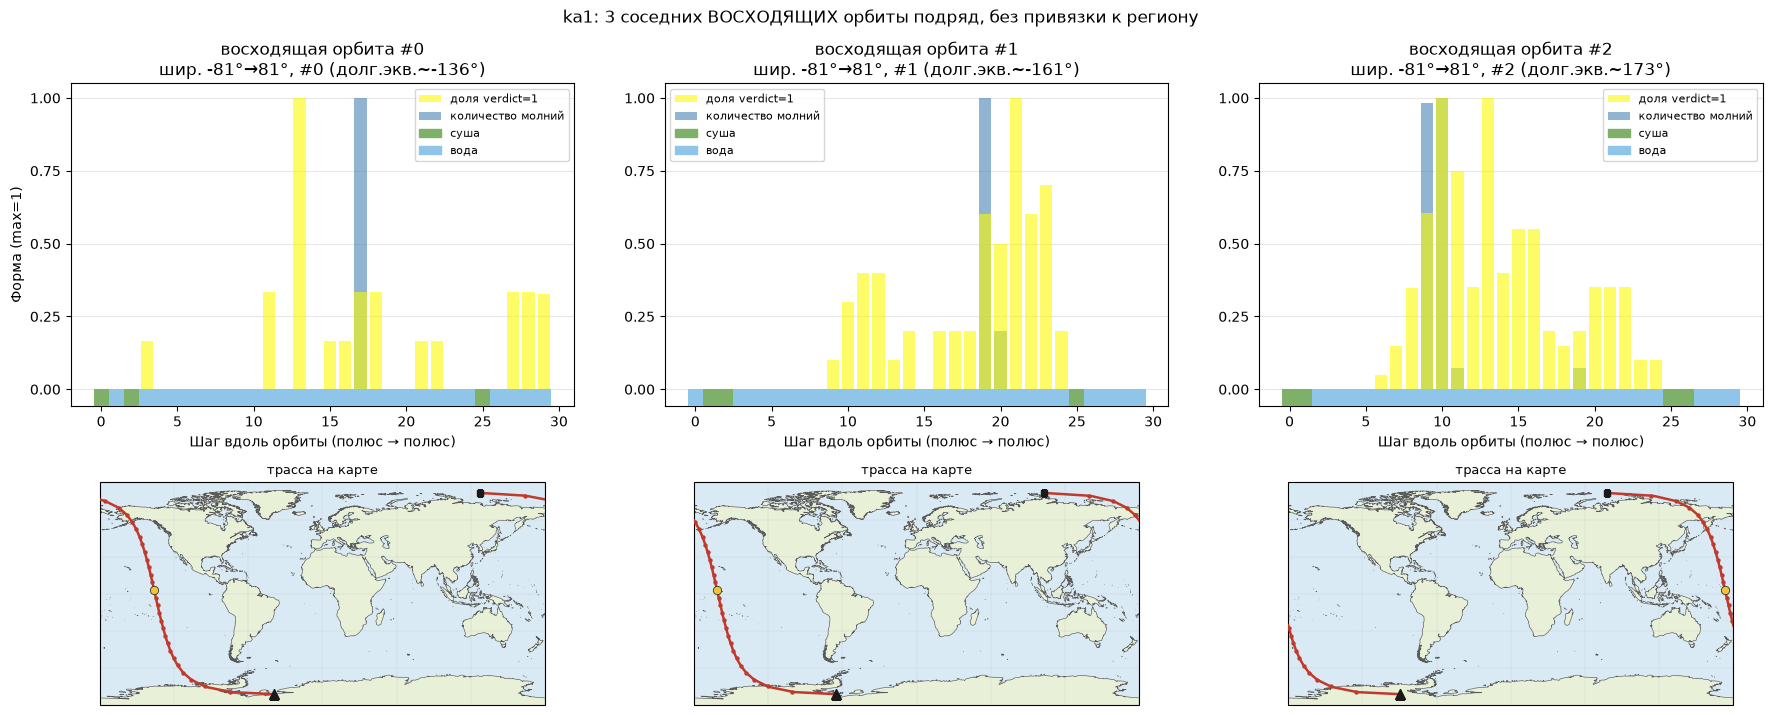

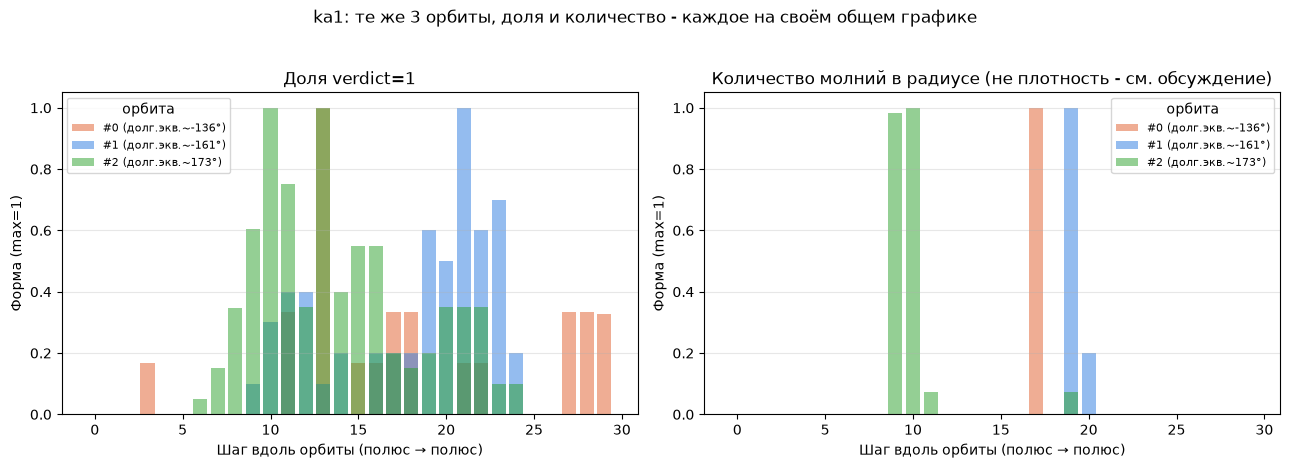

,ka1
восходящая #0,2025-01-20 17:23:42 .. 18:14:20долгота -39.4° → 127.8°
восходящая #1,2025-01-20 19:04:59 .. 19:55:35долгота -64.8° → 103.4°
восходящая #2,2025-01-20 20:46:14 .. 21:36:53долгота -89.4° → 77.5°


In [8]:
import importlib

import orbit_profile_plots as opp
importlib.reload(opp)


def plot_adjacent_orbits(START_IDX, N_ADJACENT=3, want_ascending=True):
    """Соседние полуорбиты одного направления: графики и таблица. Тело — в orbit_profile_plots.py."""
    return opp.plot_adjacent_orbits(
        START_IDX, N_ADJACENT, want_ascending,
        profiles=all_profiles, steps=steps, maxn=_maxn, sc=SC,
    )


def plot_adjacent_ascending(START_IDX, N_ADJACENT=3):
    plot_adjacent_orbits(START_IDX, N_ADJACENT, want_ascending=True)


plot_adjacent_ascending(0)  # индекс среди ВОСХОДЯЩИХ орбит (не в all_profiles напрямую)


## 6. Другие срезы тех же трёх соседних полуорбит

Пункты 6–6e повторяют рисунок п.5. Новый расчёт не вводится, меняется только место в списке (`START_IDX`) и в п.6e — направление.

Здесь `START_IDX = 25` среди восходящих.


проверка соседства: чисто, все 3 восходящих орбит идут подряд (шаг ~6077с = 101 мин, полный виток)


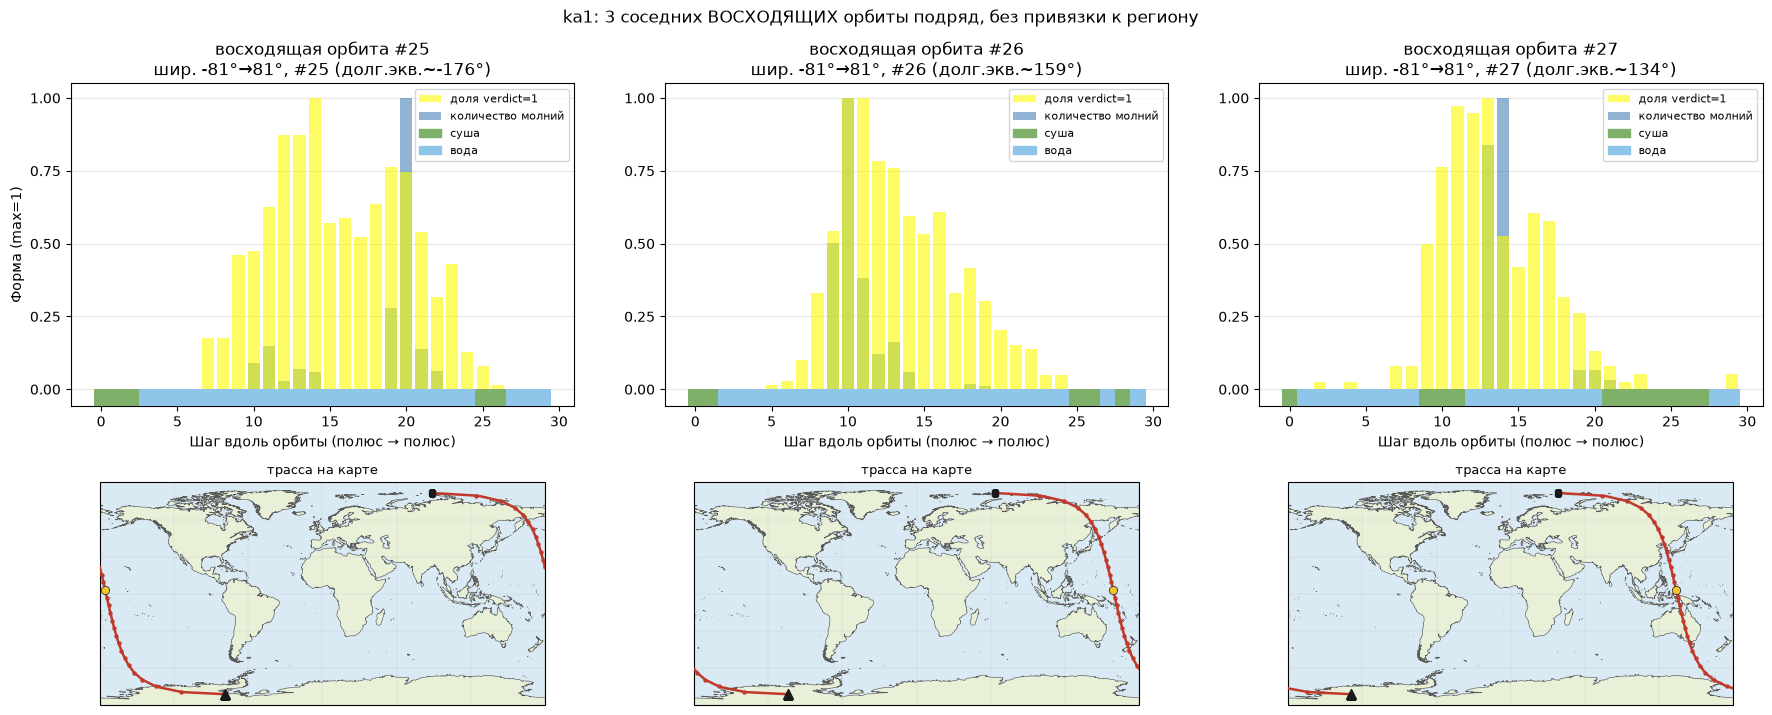

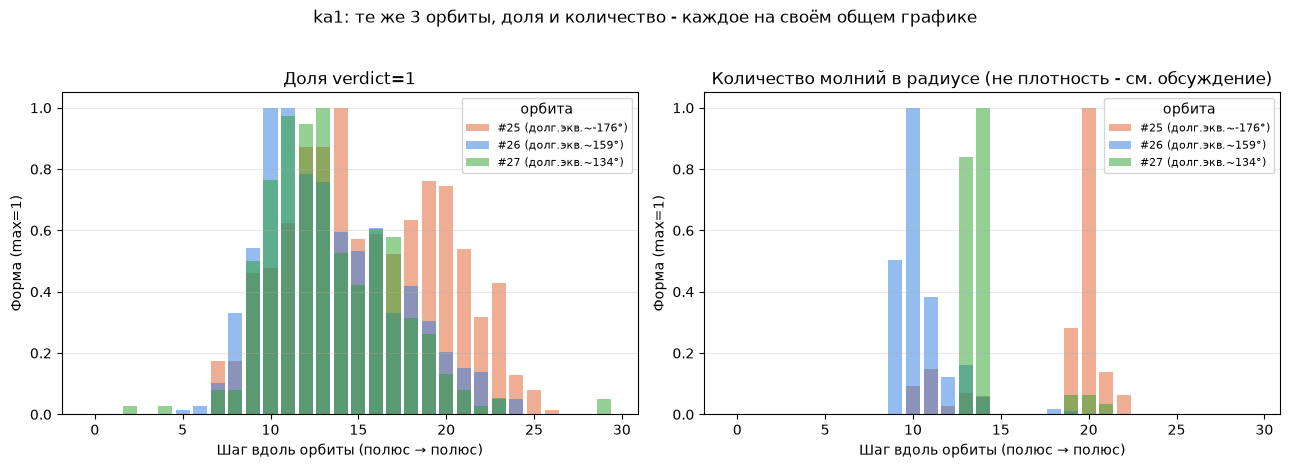

,ka1
восходящая #25,2025-01-22 20:02:04 .. 20:52:42долгота -78.9° → 88.4°
восходящая #26,2025-01-22 21:43:20 .. 22:33:58долгота -104.0° → 63.3°
восходящая #27,2025-01-22 23:24:36 .. 00:15:15долгота -129.1° → 37.9°


In [9]:
N_ADJACENT = 3
START_IDX = 25  # индекс среди ВОСХОДЯЩИХ орбит (не в all_profiles напрямую)
plot_adjacent_ascending(START_IDX, N_ADJACENT)


## 6b. Восходящие, `START_IDX = 8`

Тот же рисунок, что в п.5.


проверка соседства: чисто, все 3 восходящих орбит идут подряд (шаг ~6077с = 101 мин, полный виток)


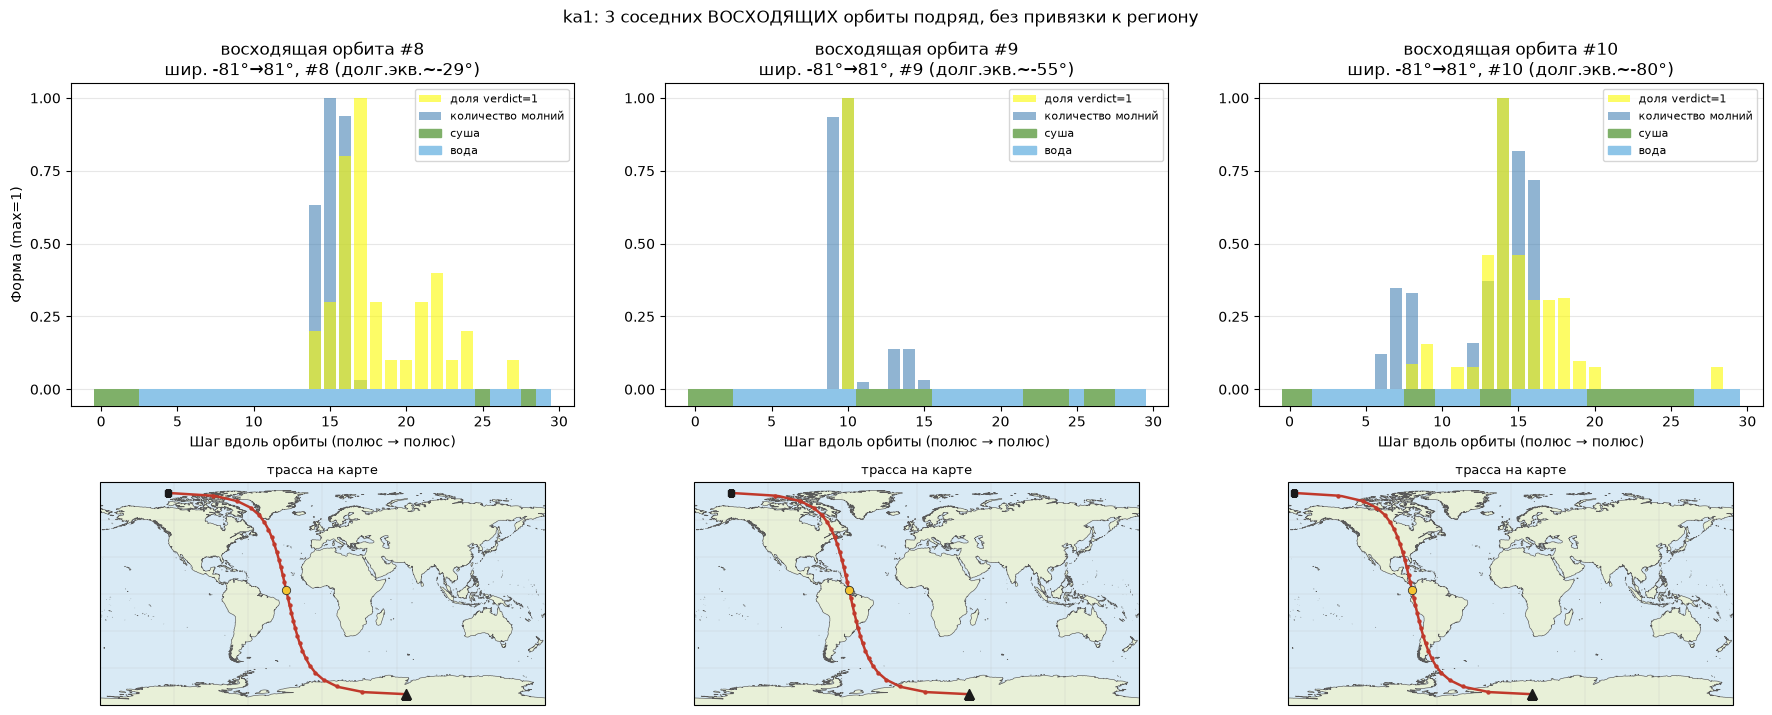

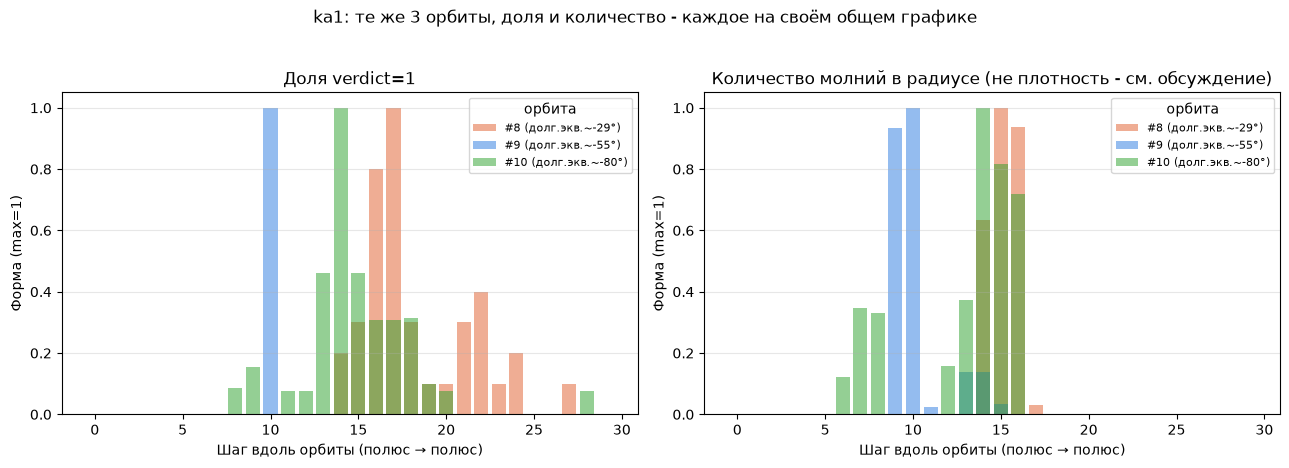

,ka1
восходящая #8,2025-01-21 10:16:28 .. 11:07:06долгота 67.9° → -124.8°
восходящая #9,2025-01-21 11:57:45 .. 12:48:23долгота 42.4° → -150.2°
восходящая #10,2025-01-21 13:39:02 .. 14:29:40долгота 17.0° → -175.7°


In [10]:
N_ADJACENT = 3
START_IDX = 8  # индекс среди ВОСХОДЯЩИХ орбит (не в all_profiles напрямую)
plot_adjacent_ascending(START_IDX, N_ADJACENT)


## 6c. Восходящие, `START_IDX = 44`

Тот же рисунок, что в п.5, срез ближе к концу 30 суток.


проверка соседства: чисто, все 3 восходящих орбит идут подряд (шаг ~6077с = 101 мин, полный виток)


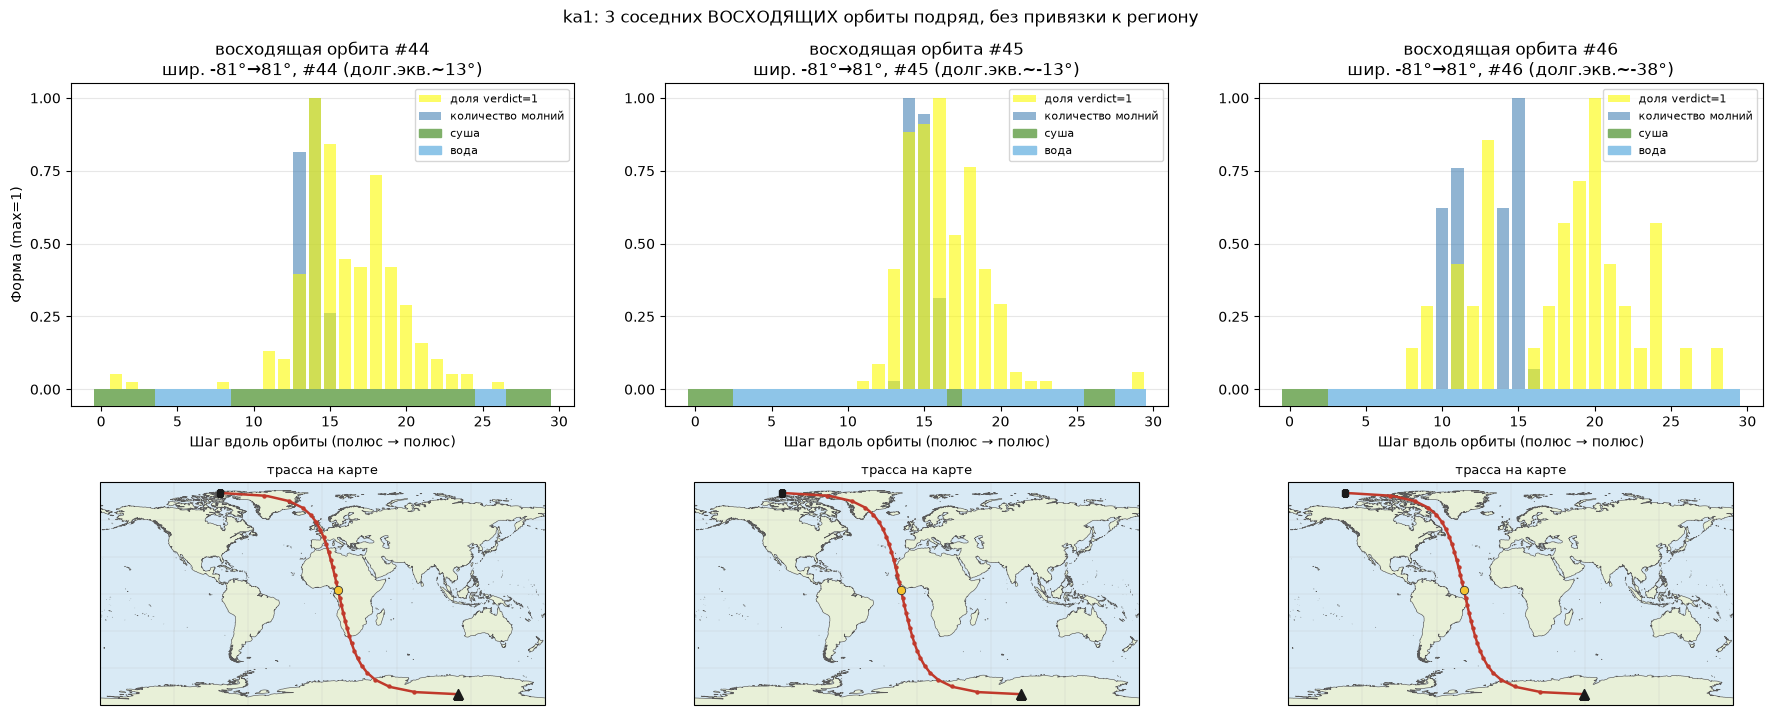

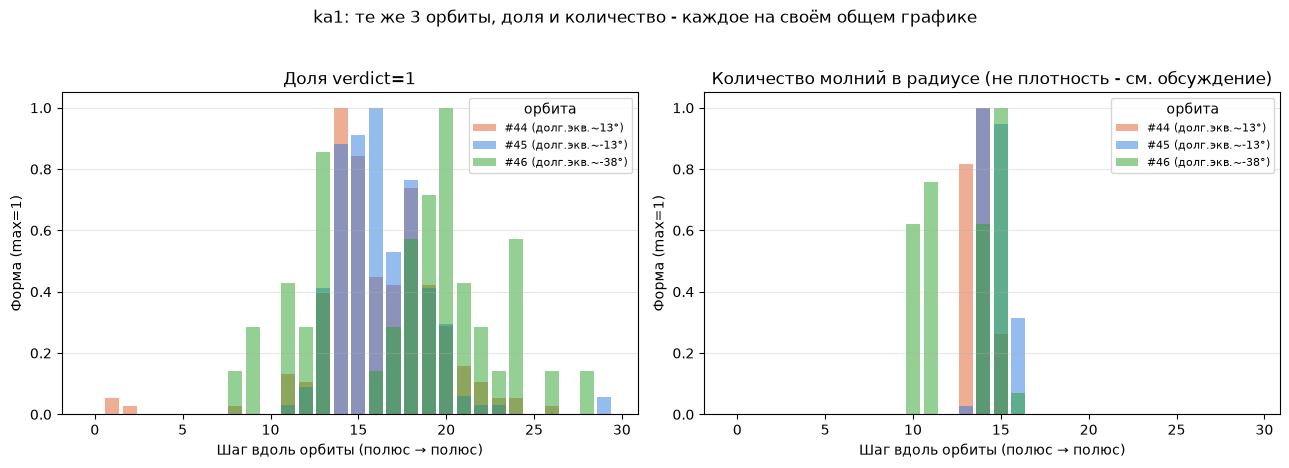

,ka1
восходящая #44,2025-01-24 07:28:54 .. 08:19:32долгота 109.7° → -82.7°
восходящая #45,2025-01-24 09:10:11 .. 10:00:50долгота 84.5° → -108.7°
восходящая #46,2025-01-24 10:51:27 .. 11:42:06долгота 59.3° → -133.7°


In [11]:
N_ADJACENT = 3
START_IDX = 44  # индекс среди ВОСХОДЯЩИХ орбит (не в all_profiles напрямую)
plot_adjacent_ascending(START_IDX, N_ADJACENT)


## 6d. Восходящие, `START_IDX = 33`

Тот же рисунок, что в п.5. Этот срез приходится на 23 января — день, которого нет в предыдущих примерах.


проверка соседства: чисто, все 3 восходящих орбит идут подряд (шаг ~6077с = 101 мин, полный виток)


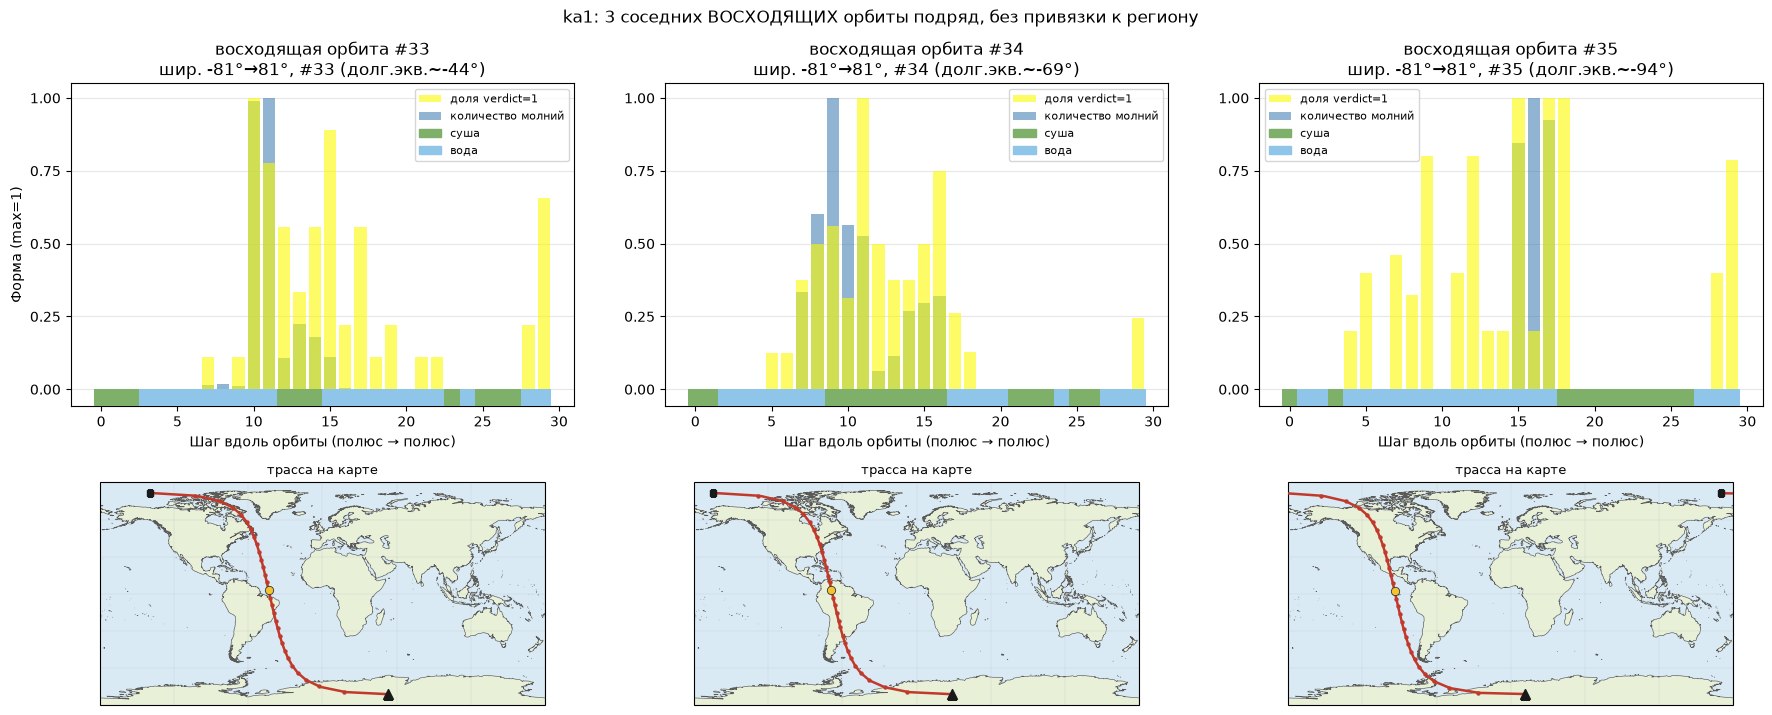

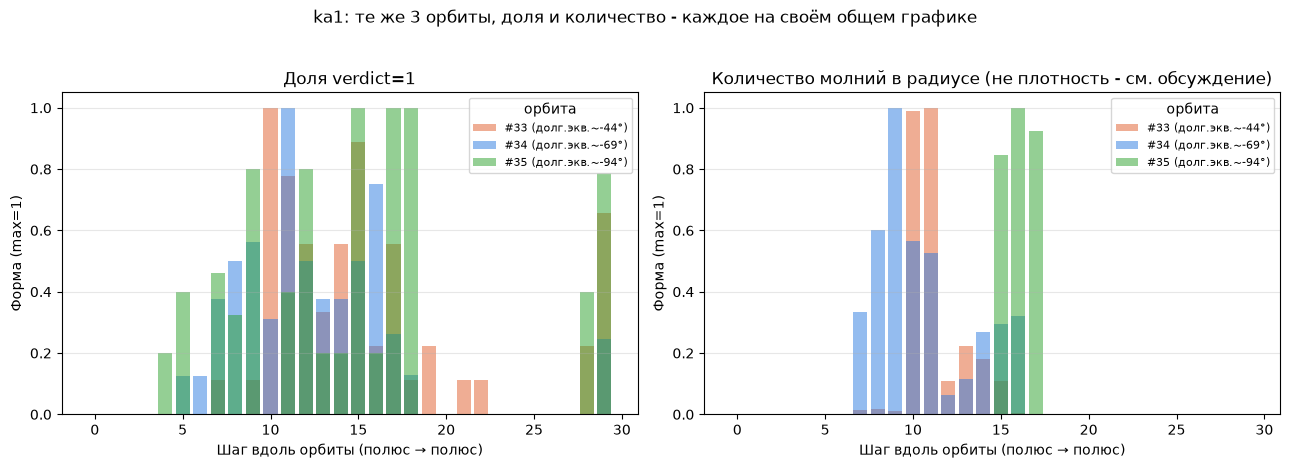

,ka1
восходящая #33,2025-01-23 11:13:34 .. 12:04:12долгота 53.4° → -139.3°
восходящая #34,2025-01-23 12:54:50 .. 13:45:28долгота 28.3° → -164.3°
восходящая #35,2025-01-23 14:35:44 .. 15:26:46долгота 11.8° → 169.9°


In [12]:
N_ADJACENT = 3
START_IDX = 33  # индекс среди ВОСХОДЯЩИХ орбит (не в all_profiles напрямую)
plot_adjacent_ascending(START_IDX, N_ADJACENT)


## 6e. Три соседние нисходящие полуорбиты

Та же логика, что в п.5, для полуорбит, у которых широта падает. `START_IDX` — номер среди нисходящих. Между двумя нисходящими лежит одна восходящая, поэтому соседние в этом списке разделены полным витком (~101 мин).


проверка соседства: чисто, все 3 нисходящих орбит идут подряд (шаг ~6077с = 101 мин, полный виток)


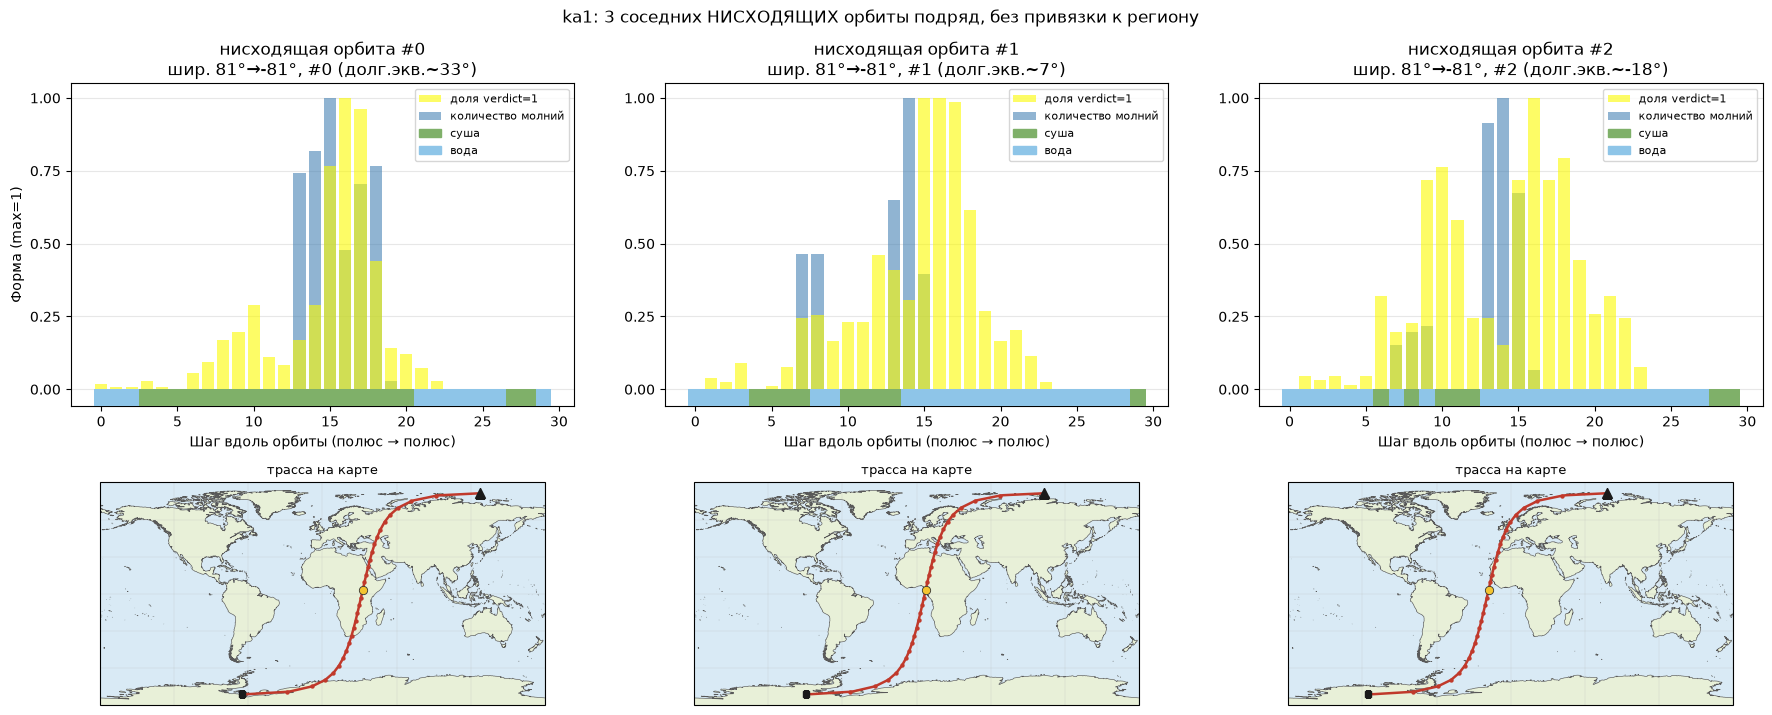

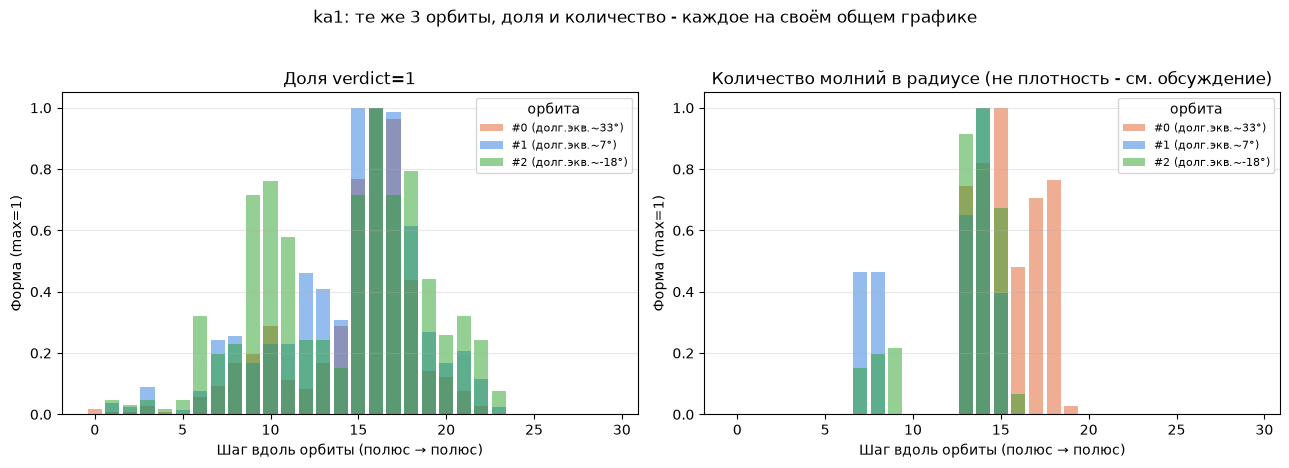

,ka1
нисходящая #0,2025-01-20 18:14:20 .. 19:04:59долгота 127.8° → -64.8°
нисходящая #1,2025-01-20 19:55:35 .. 20:46:14долгота 103.4° → -89.4°
нисходящая #2,2025-01-20 21:36:53 .. 22:27:32долгота 77.5° → -115.4°


In [13]:
N_ADJACENT = 3
START_IDX = 0  # индекс среди НИСХОДЯЩИХ орбит (не в all_profiles напрямую)
plot_adjacent_orbits(START_IDX, N_ADJACENT, want_ascending=False)


## 7. ka1 и ka2 на одной полуорбите

ka2 летит в той же плоскости, что ka1. Его восходящее пересечение экватора — ближайшее предыдущее к пересечению ka1: медиана сдвига ≈ −3017 с при полупериоде ≈ 3038 с, долгота больше примерно на 12.7°. По 359 чистым парам расстояние между трассами 1066.7 ± 0.2 км, весь размах — 2.4 км.

На рисунке слева доля `verdict=1` вдоль шагов, справа карта каждой трассы. Первый рисунок — эта ближайшая пара. Второй — «вторая подходящая» полуорбита ka2: предыдущая или следующая того же направления, у которой экватор ближе по времени к экватору ka1. Она сдвинута ещё примерно на один виток (~25° долготы) и из компактного района обычно уходит. Таблица над рисунками — время и координаты текущей полуорбиты и соседей; жирным выделены текущая и вторая подходящая.

Примеры п.7–9 не заходят в зоны высокой концентрации свистов (Африка и Карибский бассейн, они в п.8b). Берутся пары со сдвигом `|dt| < 4500` с и без пропусков в профиле `verdict`. Экватор над Тихим океаном: восходящие 94, 121 и 106 (27–30 января), нисходящие 16 и 311 (22 января и 14 февраля). П.9 — та же группа, что восходящая 94, только текущей полуорбитой считается ka2.

Ячейка ниже заново режет трек ka2 теми же правилами, что п.1–2, отдельными функциями, чтобы не затереть массивы ka1. Число молний считается прежней `lightning_count`: каталог молний от спутника не зависит. Таблица и рисунки — `orbit_profile_plots.py`.


In [14]:
%%time
df_pred_ka2 = wc.load_predictions(_paths_orb['pred'], sc_list=('ka2',), days=_orb_days)
df_pred_ka2 = df_pred_ka2.sort_values('timestamp').reset_index(drop=True)
_cutoff2 = pd.Timestamp(_orb_days[-1]) + pd.Timedelta(days=1)
df_pred_ka2 = df_pred_ka2[df_pred_ka2['timestamp'] < _cutoff2].reset_index(drop=True)

lat_ka2 = df_pred_ka2['geo_lat'].to_numpy(dtype=np.float64)
lon_ka2 = df_pred_ka2['geo_lon'].to_numpy(dtype=np.float64)
verdict_ka2 = df_pred_ka2['verdict'].to_numpy(dtype=np.int8)
t_ka2 = df_pred_ka2['timestamp'].values.astype('datetime64[s]').astype(np.int64)


def segment_orbits(lat_arr, t_arr):
    """Та же логика поиска разворотов, что в п.1 (ячейка сегментации ka1), но
    параметризовано массивами - применяем к ka2, не трогая существующие ячейки."""
    _dt = np.diff(t_arr)
    _data_gap = np.concatenate([[False], _dt > 5])
    _lat_smooth = np.convolve(lat_arr, np.ones(5) / 5, mode='same')
    _dlat = np.diff(_lat_smooth)
    _sign = np.sign(_dlat)
    _sign[_sign == 0] = 1
    _turn = np.concatenate([[False], (_sign[1:] != _sign[:-1])])
    # без сдвига - _turn[m]=True уже означает экстремум ровно в индексе m (см. п.1)
    idx = np.where(_turn)[0]
    idx = idx[~_data_gap[idx]]
    idx = idx[np.abs(_lat_smooth[idx]) >= MIN_TURN_LAT]
    keep = [idx[0]]
    for i in idx[1:]:
        if t_arr[i] - t_arr[keep[-1]] >= MIN_TURN_GAP_S:
            keep.append(i)
    return np.array(keep)


def build_orbit_profile_for(t_arr, lat_arr, lon_arr, verdict_arr, i0, i1):
    """То же, что build_orbit_profile (п.2), но принимает массивы параметром вместо
    глобальных t_all/lat_all/... - нужно для ka2. lightning_count переиспользуется как
    есть: молнии (df_ae_orb) общие для обоих спутников, от SC не зависят."""
    t0, t1 = t_arr[i0], t_arr[i1]
    if not (ORBIT_DUR_RANGE_S[0] <= (t1 - t0) <= ORBIT_DUR_RANGE_S[1]):
        return None
    step_times = np.linspace(t0, t1, N_STEPS)
    seg = (t_arr >= t0) & (t_arr <= t1)
    seg_t, seg_lat, seg_lon, seg_v = t_arr[seg], lat_arr[seg], lon_arr[seg], verdict_arr[seg]
    p_lat = np.full(N_STEPS, np.nan)
    p_lon = np.full(N_STEPS, np.nan)
    p_verdict = np.full(N_STEPS, np.nan)
    for k, st in enumerate(step_times):
        j = np.argmin(np.abs(seg_t - st))
        p_lat[k] = seg_lat[j]
        p_lon[k] = seg_lon[j]
        win = np.abs(seg_t - st) <= VERDICT_WINDOW_S
        if win.any():
            p_verdict[k] = seg_v[win].mean()
    p_count = lightning_count(p_lat, p_lon, step_times)
    p_sza = wc.solar_zenith_deg(step_times.astype('datetime64[s]'), p_lat, p_lon)
    p_night = p_sza > wc.NIGHT_SZA_DEG
    return {'t': step_times, 'lat': p_lat, 'lon': p_lon, 'verdict': p_verdict,
            'count': p_count, 'night': p_night}


turn_idx_ka2 = segment_orbits(lat_ka2, t_ka2)
all_profiles_ka2 = []
for i in range(len(turn_idx_ka2) - 1):
    prof = build_orbit_profile_for(t_ka2, lat_ka2, lon_ka2, verdict_ka2, turn_idx_ka2[i], turn_idx_ka2[i + 1])
    if prof is not None:
        all_profiles_ka2.append(prof)
print(f'ka2: точек разворота {len(turn_idx_ka2)}, построено профилей {len(all_profiles_ka2)}')

# сопоставление: для каждой восходящей орбиты ka1 - ближайшая ПРЕДЫДУЩАЯ по времени
# пересечения экватора восходящая орбита ka2 (направление зафиксировано по знаку
# медианного сдвига - ka2 обычно на ~пол-периода РАНЬШЕ ka1, см. markdown выше). Не
# "ближайшая по модулю": при двух кандидатах на равном удалении она может назначить
# двум соседним орбитам ka1 одну и ту же орбиту ka2. Берём только предыдущую.
# Если направленный поиск
# всё равно возвращает уже занятую орбиту ka2 - это значит, что несколько орбит ka2 подряд
# реально пропущены в данных (см. предупреждение ниже), а не геометрическая случайность.
ascending_ka1 = [p for p in all_profiles if p['lat'][0] < p['lat'][-1]]
ascending_ka2 = [p for p in all_profiles_ka2 if p['lat'][0] < p['lat'][-1]]
t_eq_ka2 = np.array([p['t'][np.nanargmin(np.abs(p['lat']))] for p in ascending_ka2])

pairs = []
for p1 in ascending_ka1:
    if len(t_eq_ka2) == 0:
        break
    t_eq1 = p1['t'][np.nanargmin(np.abs(p1['lat']))]
    _cand = np.where(t_eq_ka2 <= t_eq1)[0]
    if len(_cand) == 0:
        continue
    j = _cand[np.argmax(t_eq_ka2[_cand])]
    pairs.append((p1, ascending_ka2[j]))

_dts = [p2['t'][np.nanargmin(np.abs(p2['lat']))] - p1['t'][np.nanargmin(np.abs(p1['lat']))] for p1, p2 in pairs]
_med_dt = np.median(_dts)
print(f'сопоставленных пар (восходящие): {len(pairs)}, dt (ka2-ka1): медиана={_med_dt:.0f}с, '
      f'мин={np.min(_dts):.0f}с, макс={np.max(_dts):.0f}с')

# несколько орбит ka2 подряд пропущены -> |dt| в разы больше медианы (нечётные кратные
# полупериода: 1x — обычный сосед, 3x/5x/7x — пропуск нескольких полуорбит ka2)
_bad_pairs = [(i, d) for i, d in enumerate(_dts) if abs(d) > 1.5 * abs(_med_dt)]
if _bad_pairs:
    print(f'⚠ {len(_bad_pairs)} из {len(pairs)} пар (восходящие) с |dt| > 1.5×медианы - '
          f'скорее всего несколько орбит ka2 подряд пропущены, это НЕ тот же физический '
          f'полувиток, а дальний суррогат:')
    for i, d in _bad_pairs:
        print(f'  pairs[{i}]: dt={d:.0f}с (норма ~{_med_dt:.0f}с)')


ka2: 30 файлов из /Users/user/Downloads/wwlln/predictions/whistler_binary/ka2
ka2: точек разворота 781, построено профилей 750
сопоставленных пар (восходящие): 379, dt (ka2-ka1): медиана=-3017с, мин=-27412с, макс=-2179с
⚠ 38 из 379 пар (восходящие) с |dt| > 1.5×медианы - скорее всего несколько орбит ka2 подряд пропущены, это НЕ тот же физический полувиток, а дальний суррогат:
  pairs[0]: dt=-9094с (норма ~-3017с)
  pairs[3]: dt=-15157с (норма ~-3017с)
  pairs[15]: dt=-9093с (норма ~-3017с)
  pairs[27]: dt=-9095с (норма ~-3017с)
  pairs[28]: dt=-15172с (норма ~-3017с)
  pairs[41]: dt=-15171с (норма ~-3017с)
  pairs[42]: dt=-21247с (норма ~-3017с)
  pairs[51]: dt=-9094с (норма ~-3017с)
  pairs[52]: dt=-15170с (норма ~-3017с)
  pairs[53]: dt=-21246с (норма ~-3017с)
  pairs[54]: dt=-27324с (норма ~-3017с)
  pairs[56]: dt=-9093с (норма ~-3017с)
  pairs[64]: dt=-9094с (норма ~-3017с)
  pairs[68]: dt=-9094с (норма ~-3017с)
  pairs[69]: dt=-15171с (норма ~-3017с)
  pairs[70]: dt=-21248с (норма

,ka1,ka2
предыдущий восходящий,"2025-01-27 21:34:07 .. 22:24:45широта -81.3° → 81.3°, долгота -101.5° → 65.8°","2025-01-27 20:43:49 .. 21:34:28широта -81.3° → 81.3°, долгота -88.9° → 78.3°"
предыдущий нисходящий,"2025-01-27 22:24:45 .. 23:15:24широта 81.3° → -81.3°, долгота 65.8° → -127.0°","2025-01-27 21:34:28 .. 22:25:05широта 81.3° → -81.3°, долгота 78.3° → -114.0°"
текущая,"2025-01-27 23:15:24 .. 00:06:02широта -81.3° → 81.3°, долгота -127.0° → 40.4°","2025-01-27 22:25:05 .. 23:15:45широта -81.3° → 81.3°, долгота -114.0° → 52.8°"
следующий нисходящий,"2025-01-28 00:06:02 .. 00:56:40широта 81.3° → -81.3°, долгота 40.4° → -152.0°","2025-01-27 23:15:45 .. 00:06:23широта 81.3° → -81.3°, долгота 52.8° → -139.8°"
следующий восходящий,"2025-01-28 00:56:40 .. 01:47:19широта -81.3° → 81.3°, долгота -152.0° → 14.9°","2025-01-28 00:06:23 .. 00:57:02широта -81.3° → 81.3°, долгота -139.8° → 27.4°"


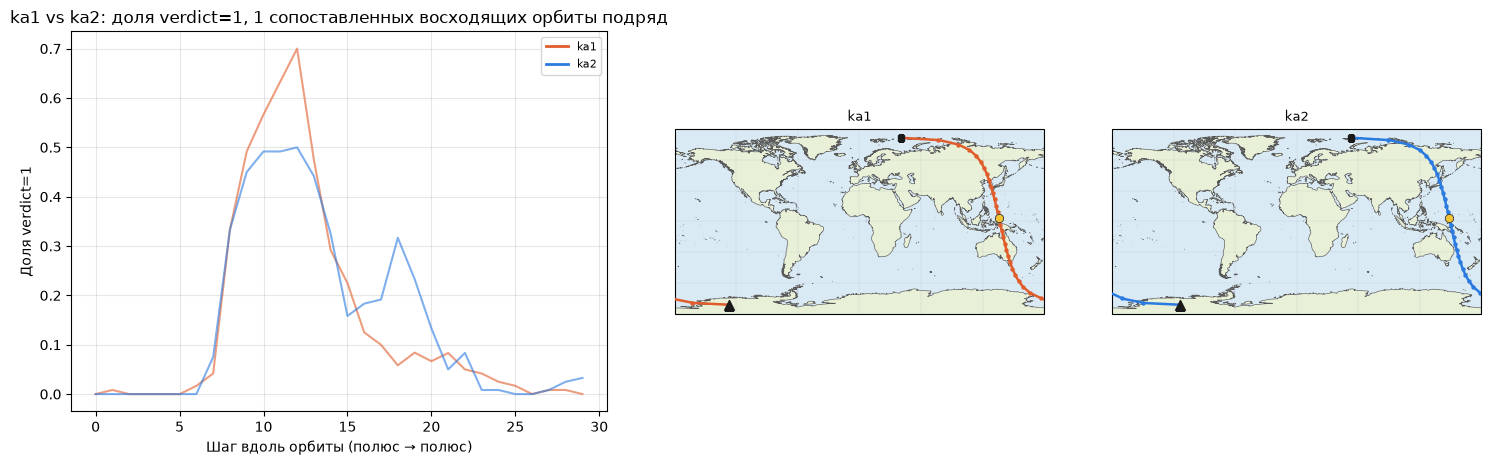

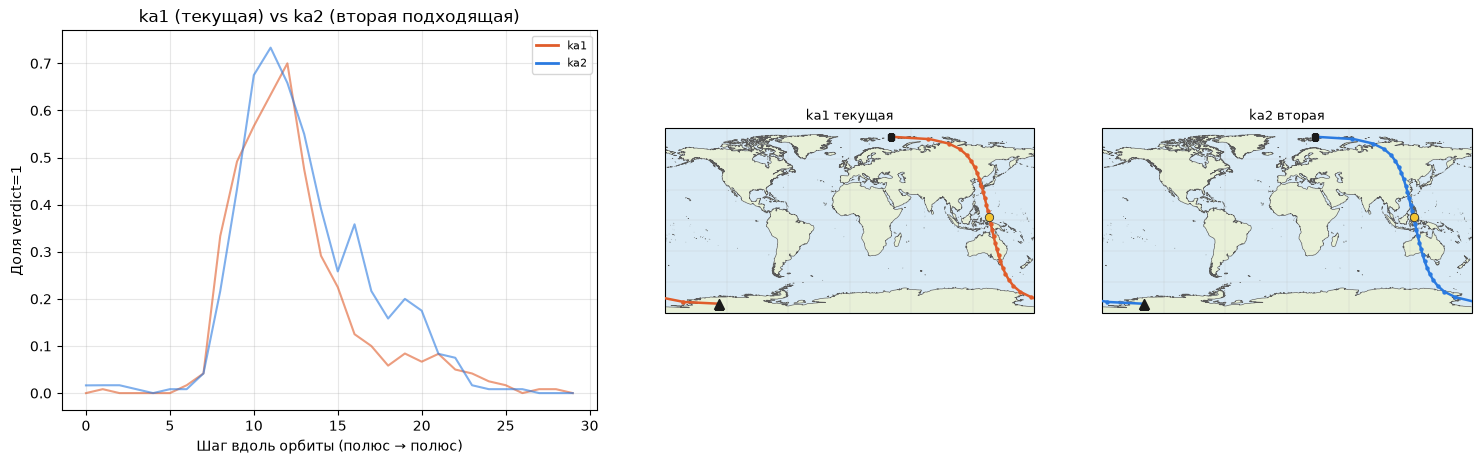

In [15]:
import importlib

import orbit_profile_plots as opp
importlib.reload(opp)

N_ADJACENT_KA = 1
START_IDX_KA = 94  # 2025-01-27, Тихий океан. Вне зон высокой концентрации (Африка, Карибы).
                   # Профили без NaN, dt=-3018 с.
pairs_sel = pairs[START_IDX_KA:START_IDX_KA + N_ADJACENT_KA]


def _orbit_table(p_primary, p_secondary, primary_profs=None, secondary_profs=None,
                 want_ascending=True, primary_name='ka1', secondary_name='ka2'):
    """Таблица соседних полувитков ka1/ka2. Тело — в orbit_profile_plots.py."""
    return opp._orbit_table(
        p_primary, p_secondary, primary_profs, secondary_profs,
        want_ascending=want_ascending, primary_name=primary_name, secondary_name=secondary_name,
        profiles_by_name={'ka1': all_profiles, 'ka2': all_profiles_ka2},
    )


def plot_verdict_pair_with_maps(tracks, title, legend_handles=None):
    """Доля verdict=1 и карты трасс. Тело — в orbit_profile_plots.py."""
    return opp.plot_verdict_pair_with_maps(tracks, title, legend_handles, steps=steps)


_cell_html = opp._cell_html

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title=f'ka1 vs ka2: доля verdict=1, {len(pairs_sel)} сопоставленных восходящих орбиты подряд',
)

# --- второй график: ka1 (текущая) vs ka2 (вторая подходящая) ---
p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая)',
)


,ka1,ka2
предыдущий восходящий,"2025-01-29 22:31:12 .. 23:21:50широта -81.3° → 81.3°, долгота -115.9° → 51.5°","2025-01-29 21:40:55 .. 22:31:33широта -81.3° → 81.3°, долгота -103.6° → 64.0°"
предыдущий нисходящий,"2025-01-29 23:21:50 .. 00:12:28широта 81.3° → -81.3°, долгота 51.5° → -140.9°","2025-01-29 22:31:33 .. 23:22:11широта 81.3° → -81.3°, долгота 64.0° → -128.7°"
текущая,"2025-01-30 00:12:28 .. 01:03:07широта -81.3° → 81.3°, долгота -140.9° → 26.0°","2025-01-29 23:22:11 .. 00:12:49широта -81.3° → 81.3°, долгота -128.7° → 38.9°"
следующий нисходящий,"2025-01-30 01:03:07 .. 01:53:45широта 81.3° → -81.3°, долгота 26.0° → -166.4°","2025-01-30 00:12:49 .. 01:03:27широта 81.3° → -81.3°, долгота 38.9° → -153.7°"
следующий восходящий,"2025-01-30 01:53:45 .. 02:44:24широта -81.3° → 81.3°, долгота -166.4° → 0.6°","2025-01-30 01:03:27 .. 01:54:06широта -81.3° → 81.3°, долгота -153.7° → 13.5°"


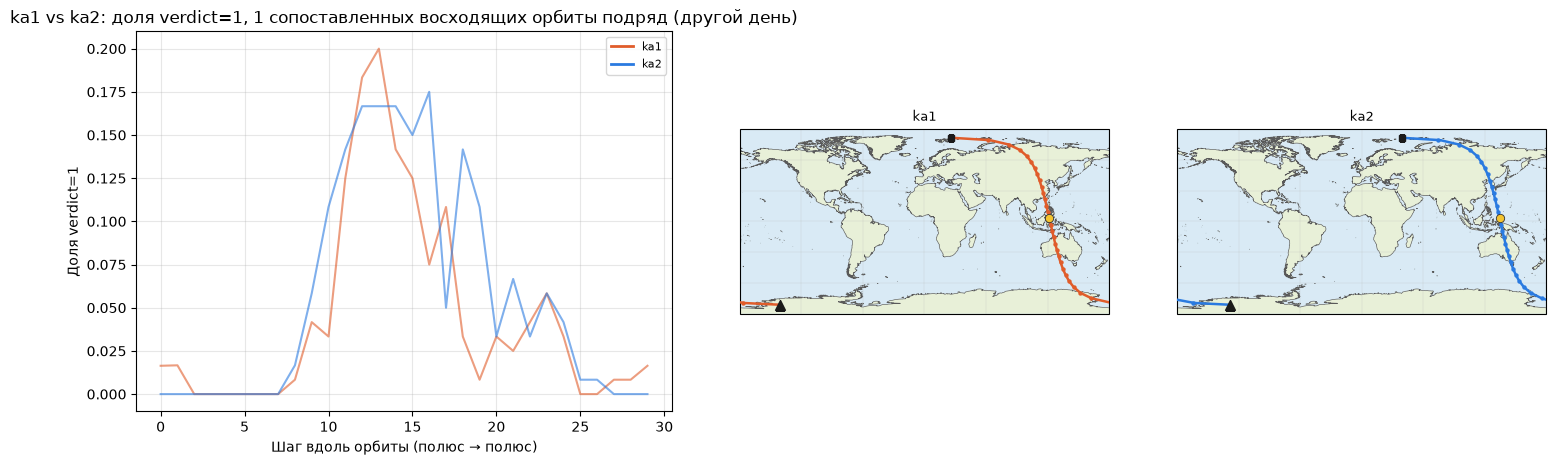

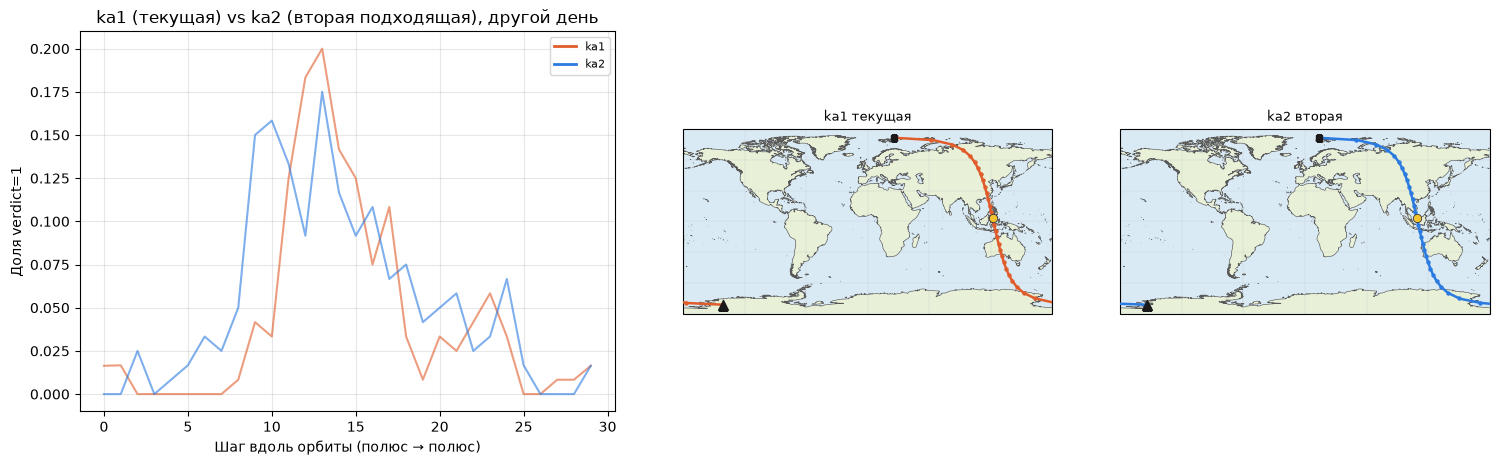

In [16]:
N_ADJACENT_KA = 1
START_IDX_KA = 121  # 2025-01-30, Тихий океан. Вне зон высокой концентрации (Африка, Карибы).
                    # Профили без NaN, dt=-3018 с.
pairs_sel = pairs[START_IDX_KA:START_IDX_KA + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title=f'ka1 vs ka2: доля verdict=1, {len(pairs_sel)} сопоставленных восходящих орбиты подряд (другой день)',
)

# --- второй график: ka1 (текущая) vs ka2 (вторая подходящая) ---
p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), другой день',
)

,ka1,ka2
предыдущий восходящий,"2025-01-28 21:12:02 .. 22:02:40широта -81.3° → 81.3°, долгота -96.3° → 71.0°","2025-01-28 20:21:44 .. 21:12:22широта -81.3° → 81.3°, долгота -83.7° → 83.9°"
предыдущий нисходящий,"2025-01-28 22:02:40 .. 22:53:18широта 81.3° → -81.3°, долгота 71.0° → -121.4°","2025-01-28 21:12:22 .. 22:03:00широта 81.3° → -81.3°, долгота 83.9° → -108.8°"
текущая,"2025-01-28 22:53:18 .. 23:43:56широта -81.3° → 81.3°, долгота -121.4° → 45.9°","2025-01-28 22:03:00 .. 22:53:39широта -81.3° → 81.3°, долгота -108.8° → 58.4°"
следующий нисходящий,"2025-01-28 23:43:56 .. 00:34:34широта 81.3° → -81.3°, долгота 45.9° → -146.5°","2025-01-28 22:53:39 .. 23:44:16широта 81.3° → -81.3°, долгота 58.4° → -133.8°"
следующий восходящий,"2025-01-29 00:34:34 .. 01:25:13широта -81.3° → 81.3°, долгота -146.5° → 20.5°","2025-01-28 23:44:16 .. 00:34:55широта -81.3° → 81.3°, долгота -133.8° → 33.4°"


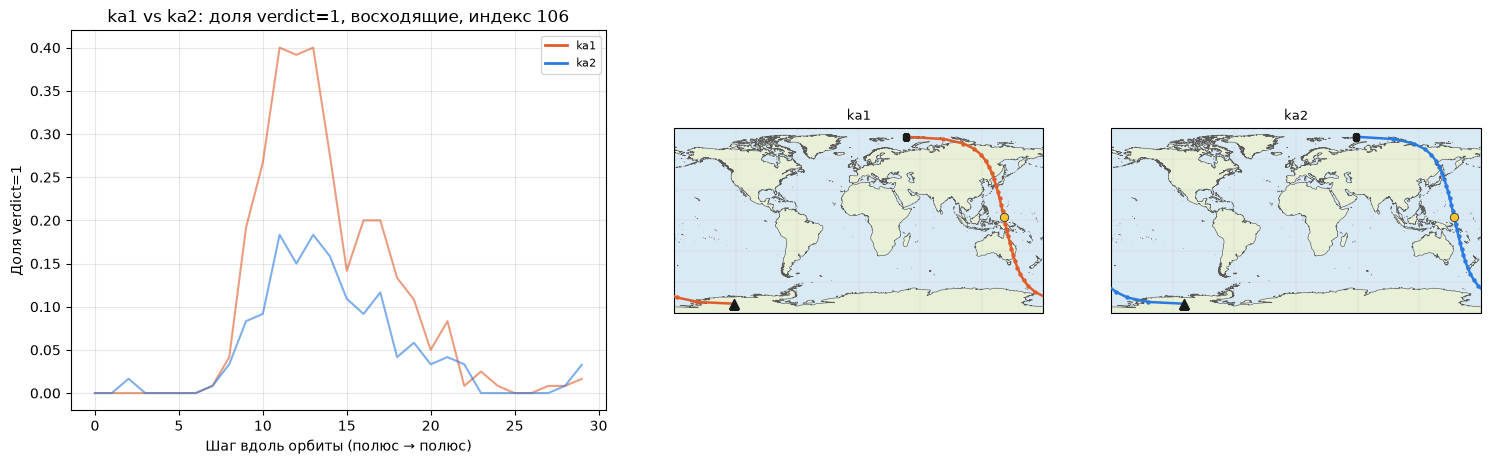

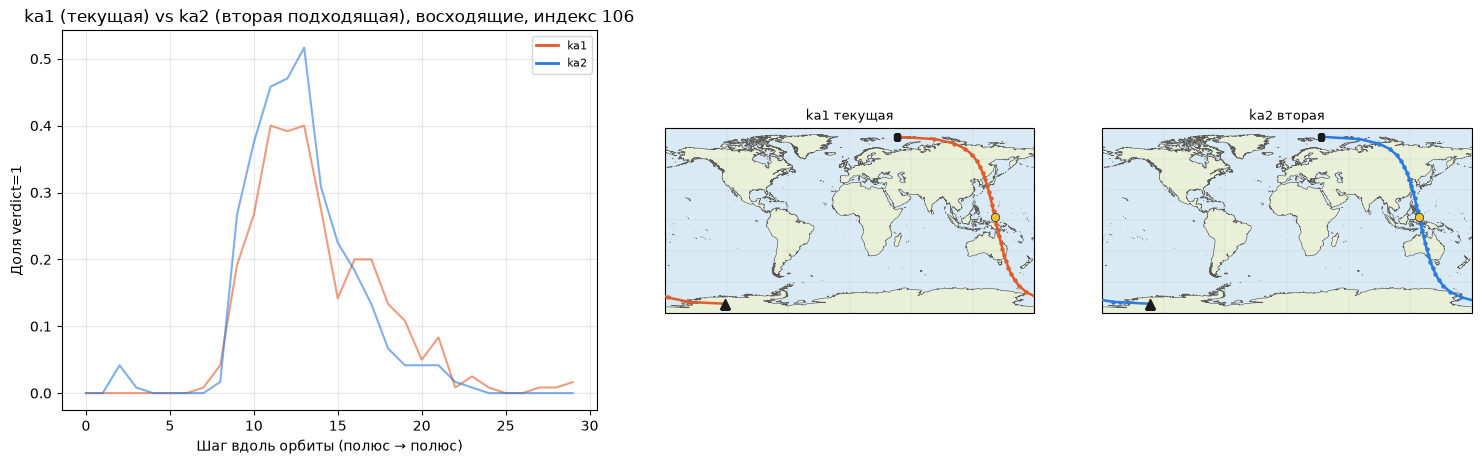

In [25]:
N_ADJACENT_KA = 1
START_IDX_KA = 106  # 2025-01-28, Тихий океан. Вне зон высокой концентрации (Африка, Карибы).
                    # Профили без NaN, dt=-3017 с.
pairs_sel = pairs[START_IDX_KA:START_IDX_KA + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title=f'ka1 vs ka2: доля verdict=1, восходящие, индекс {START_IDX_KA}',
)

# --- второй график: ka1 (текущая) vs ka2 (вторая подходящая) ---
p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), восходящие, индекс 106',
)


## 8. То же сопоставление для нисходящих

Правило то же, что в п.7, для полуорбит, у которых широта падает. Список пар называется `pairs_desc` и с восходящим списком `pairs` не смешивается. Первая ячейка строит этот список и рисует нисходящую 16 (22 января). Следующая — нисходящую 311 (14 февраля). Обе над Тихим океаном, вне зон из п.8b.


сопоставленных пар (нисходящие): 374, dt (ka2-ka1): медиана=-3017с, мин=-57708с, макс=-1866с
⚠ 36 из 374 пар (нисходящие) с |dt| > 1.5×медианы - скорее всего несколько орбит ka2 подряд пропущены, это НЕ тот же физический полувиток, а дальний суррогат:
  pairs_desc[0]: dt=-15171с (норма ~-3017с)
  pairs_desc[3]: dt=-15171с (норма ~-3017с)
  pairs_desc[14]: dt=-9093с (норма ~-3017с)
  pairs_desc[26]: dt=-9095с (норма ~-3017с)
  pairs_desc[27]: dt=-15172с (норма ~-3017с)
  pairs_desc[40]: dt=-15171с (норма ~-3017с)
  pairs_desc[41]: dt=-21353с (норма ~-3017с)
  pairs_desc[50]: dt=-8995с (норма ~-3017с)
  pairs_desc[51]: dt=-15071с (норма ~-3017с)
  pairs_desc[52]: dt=-21148с (норма ~-3017с)
  pairs_desc[55]: dt=-9093с (норма ~-3017с)
  pairs_desc[62]: dt=-9093с (норма ~-3017с)
  pairs_desc[63]: dt=-15170с (норма ~-3017с)
  pairs_desc[67]: dt=-9094с (норма ~-3017с)
  pairs_desc[68]: dt=-15171с (норма ~-3017с)
  pairs_desc[69]: dt=-21248с (норма ~-3017с)
  pairs_desc[75]: dt=-14647с (норма 

,ka1,ka2
предыдущий нисходящий,"2025-01-22 05:41:10 .. 06:31:49широта 81.3° → -81.3°, долгота -43.2° → 124.0°","2025-01-22 04:50:54 .. 05:41:30широта 81.3° → -81.3°, долгота -31.0° → 137.3°"
предыдущий восходящий,"2025-01-22 06:31:49 .. 07:22:28широта -81.3° → 81.3°, долгота 124.0° → -69.0°","2025-01-22 05:41:30 .. 06:32:10широта -81.3° → 81.3°, долгота 137.3° → -55.9°"
текущая,"2025-01-22 07:22:28 .. 08:13:06широта 81.3° → -81.3°, долгота -69.0° → 98.6°","2025-01-22 06:32:10 .. 07:22:48широта 81.3° → -81.3°, долгота -55.9° → 111.3°"
следующий восходящий,"2025-01-22 08:13:06 .. 09:03:44широта -81.3° → 81.3°, долгота 98.6° → -94.1°","2025-01-22 07:22:48 .. 08:13:28широта -81.3° → 81.3°, долгота 111.3° → -81.8°"
следующий нисходящий,"2025-01-22 09:03:44 .. 09:54:22широта 81.3° → -81.3°, долгота -94.1° → 73.5°","2025-01-22 08:13:28 .. 09:04:06широта 81.3° → -81.3°, долгота -81.8° → 85.4°"


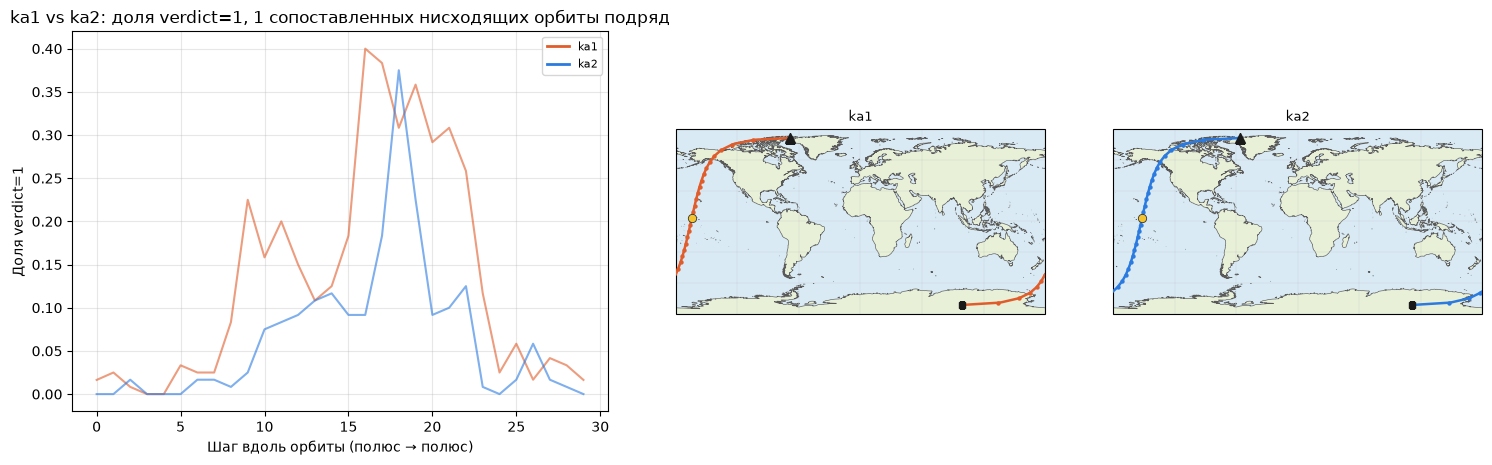

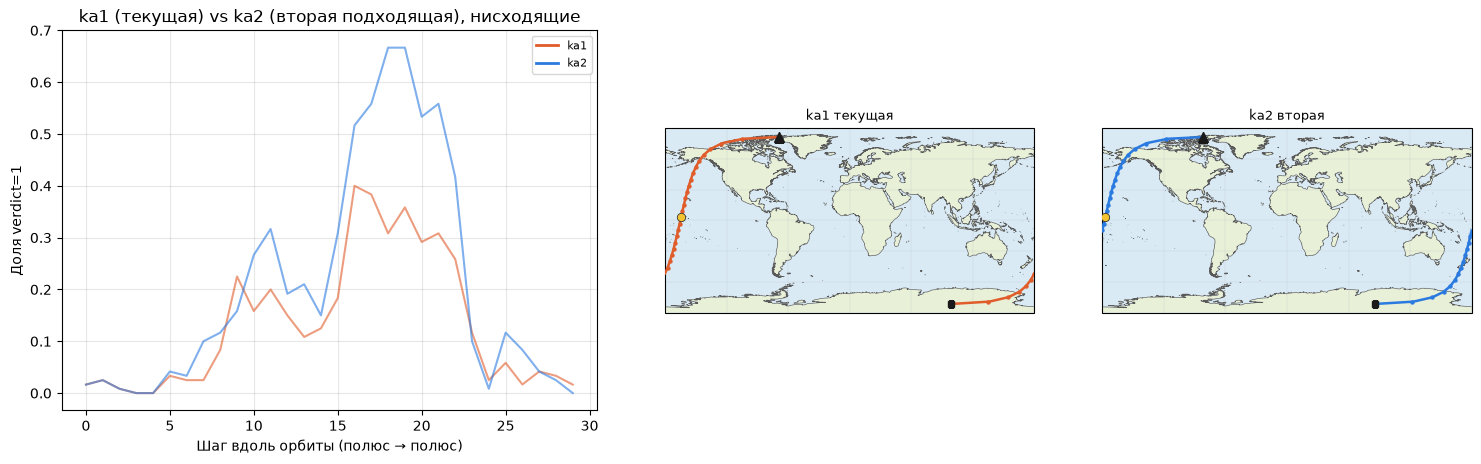

In [17]:
# сопоставление нисходящих: та же логика, что pairs в п.7 (только предыдущая по экватору;
# |dt| в разы больше медианы — пропуск телеметрии). Широта в начале > в конце.
# Отдельный список, с восходящими не смешивается
descending_ka1 = [p for p in all_profiles if p['lat'][0] > p['lat'][-1]]
descending_ka2 = [p for p in all_profiles_ka2 if p['lat'][0] > p['lat'][-1]]
t_eq_ka2_desc = np.array([p['t'][np.nanargmin(np.abs(p['lat']))] for p in descending_ka2])

pairs_desc = []
for p1 in descending_ka1:
    if len(t_eq_ka2_desc) == 0:
        break
    t_eq1 = p1['t'][np.nanargmin(np.abs(p1['lat']))]
    _cand = np.where(t_eq_ka2_desc <= t_eq1)[0]
    if len(_cand) == 0:
        continue
    j = _cand[np.argmax(t_eq_ka2_desc[_cand])]
    pairs_desc.append((p1, descending_ka2[j]))

_dts_desc = [p2['t'][np.nanargmin(np.abs(p2['lat']))] - p1['t'][np.nanargmin(np.abs(p1['lat']))] for p1, p2 in pairs_desc]
_med_dt_desc = np.median(_dts_desc)
print(f'сопоставленных пар (нисходящие): {len(pairs_desc)}, dt (ka2-ka1): медиана={_med_dt_desc:.0f}с, '
      f'мин={np.min(_dts_desc):.0f}с, макс={np.max(_dts_desc):.0f}с')

_bad_pairs_desc = [(i, d) for i, d in enumerate(_dts_desc) if abs(d) > 1.5 * abs(_med_dt_desc)]
if _bad_pairs_desc:
    print(f'⚠ {len(_bad_pairs_desc)} из {len(pairs_desc)} пар (нисходящие) с |dt| > 1.5×медианы - '
          f'скорее всего несколько орбит ka2 подряд пропущены, это НЕ тот же физический '
          f'полувиток, а дальний суррогат:')
    for i, d in _bad_pairs_desc:
        print(f'  pairs_desc[{i}]: dt={d:.0f}с (норма ~{_med_dt_desc:.0f}с)')

N_ADJACENT_KA = 1
START_IDX_KA_DESC = 16  # 2025-01-22, Тихий океан. Вне зон высокой концентрации (Африка, Карибы).
                        # Профили без NaN, dt=-3018 с.
pairs_sel = pairs_desc[START_IDX_KA_DESC:START_IDX_KA_DESC + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2, want_ascending=False))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title=f'ka1 vs ka2: доля verdict=1, {len(pairs_sel)} сопоставленных нисходящих орбиты подряд',
)

# --- второй график: ka1 (текущая) vs ka2 (вторая подходящая) ---
p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), нисходящие',
)


,ka1,ka2
предыдущий нисходящий,"2025-02-14 05:39:16 .. 06:29:54широта 81.3° → -81.3°, долгота -43.1° → 124.5°","2025-02-14 04:48:59 .. 05:39:37широта 81.3° → -81.3°, долгота -30.4° → 137.0°"
предыдущий восходящий,"2025-02-14 06:29:54 .. 07:20:32широта -81.3° → 81.3°, долгота 124.5° → -68.1°","2025-02-14 05:39:37 .. 06:30:15широта -81.3° → 81.3°, долгота 137.0° → -55.4°"
текущая,"2025-02-14 07:20:32 .. 08:11:10широта 81.3° → -81.3°, долгота -68.1° → 99.4°","2025-02-14 06:30:15 .. 07:20:53широта 81.3° → -81.3°, долгота -55.4° → 112.0°"
следующий восходящий,"2025-02-14 08:11:10 .. 09:01:49широта -81.3° → 81.3°, долгота 99.4° → -93.6°","2025-02-14 07:20:53 .. 08:11:32широта -81.3° → 81.3°, долгота 112.0° → -80.9°"
следующий нисходящий,"2025-02-14 09:01:49 .. 09:52:27широта 81.3° → -81.3°, долгота -93.6° → 73.9°","2025-02-14 08:11:32 .. 09:02:10широта 81.3° → -81.3°, долгота -80.9° → 86.5°"


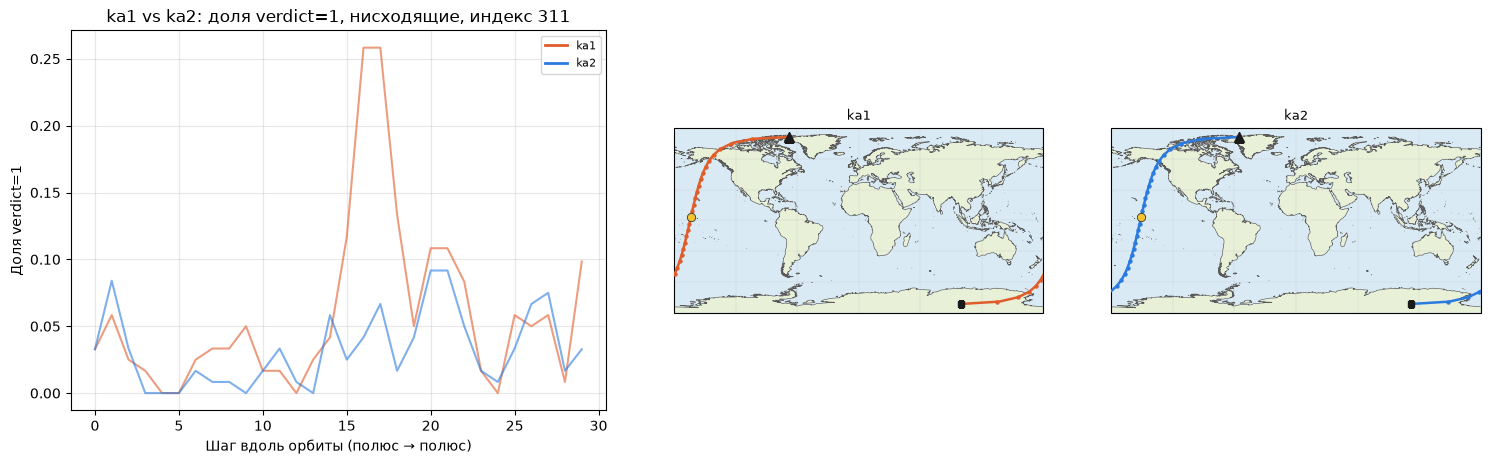

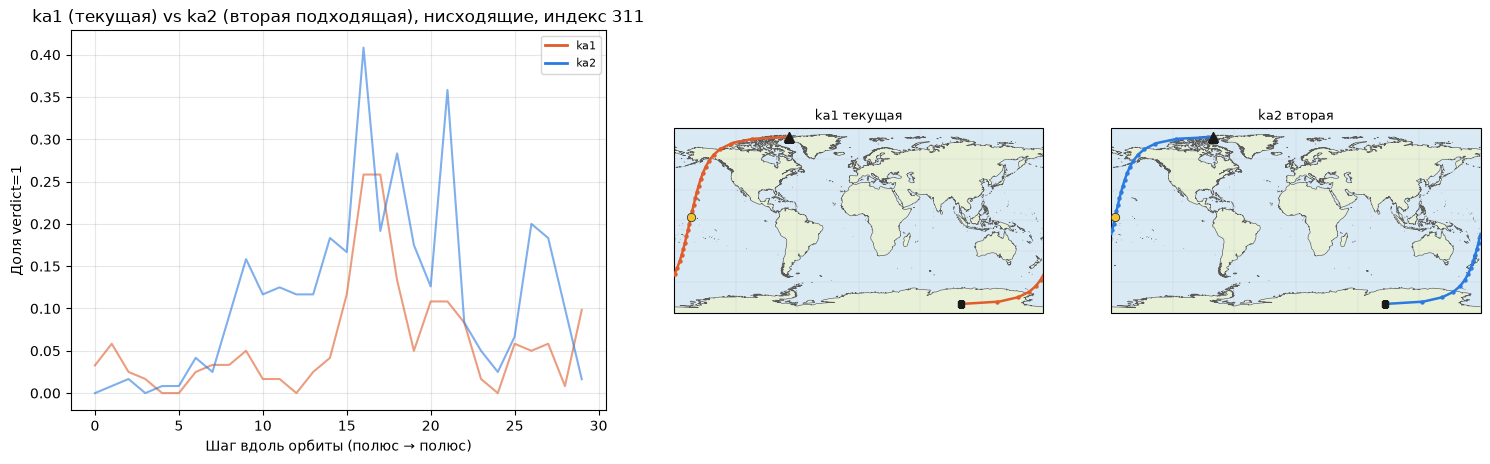

In [26]:
N_ADJACENT_KA = 1
START_IDX_KA_DESC = 311  # 2025-02-14, Тихий океан. Вне зон высокой концентрации (Африка, Карибы).
                         # Профили без NaN, dt=-3017 с.
pairs_sel = pairs_desc[START_IDX_KA_DESC:START_IDX_KA_DESC + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2, want_ascending=False))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title=f'ka1 vs ka2: доля verdict=1, нисходящие, индекс {START_IDX_KA_DESC}',
)

# --- второй график: ka1 (текущая) vs ka2 (вторая подходящая) ---
p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), нисходящие, индекс 311',
)


## 8b. Проходы через зоны высокой концентрации свистов

Те же пары и те же два рисунка, что в п.7–8. Здесь экватор обоих аппаратов лежит в одной такой зоне. Примеры п.7–9 эту зону не пересекают.

- Карибы, рамка как в п.3 (`0…25°N`, `−90…−60°E`). Восходящие 186 (3 февраля, экватор −83° / −71°) и 143 (31 января, −75° / −62°). Нисходящие 286 (12 февраля, −74° / −61°) и 106 (29 января, −76° / −63°). В каждой паре оба трека ещё внутри бассейна.
- Африка: Гвинейский залив, нисходящая 24 (22 января, −8° / +5°); Центральная Африка, восходящая 72 (26 января, +24° / +37°).

«Вторая подходящая» полуорбита сдвинута ещё на период (~25° долготы) и из зоны обычно выходит. Про зону говорится про первую, ближайшую пару.


,ka1,ka2
предыдущий нисходящий,"2025-02-11 23:38:21 .. 00:28:59широта 81.3° → -81.3°, долгота 47.4° → -145.0°","2025-02-11 22:48:03 .. 23:38:42широта 81.3° → -81.3°, долгота 60.5° → -132.5°"
предыдущий восходящий,"2025-02-12 00:28:59 .. 01:19:38широта -81.3° → 81.3°, долгота -145.0° → 22.0°","2025-02-11 23:38:42 .. 00:29:21широта -81.3° → 81.3°, долгота -132.5° → 34.6°"
текущая,"2025-02-12 01:19:38 .. 02:10:16широта 81.3° → -81.3°, долгота 22.0° → -170.5°","2025-02-12 00:29:21 .. 01:19:59широта 81.3° → -81.3°, долгота 34.6° → -157.9°"
следующий восходящий,"2025-02-12 02:10:16 .. 03:00:54широта -81.3° → 81.3°, долгота -170.5° → -3.0°","2025-02-12 01:19:59 .. 02:10:38широта -81.3° → 81.3°, долгота -157.9° → 9.2°"
следующий нисходящий,"2025-02-12 03:00:54 .. 03:51:33широта 81.3° → -81.3°, долгота -3.0° → 164.1°","2025-02-12 02:10:38 .. 03:01:15широта 81.3° → -81.3°, долгота 9.2° → 177.0°"


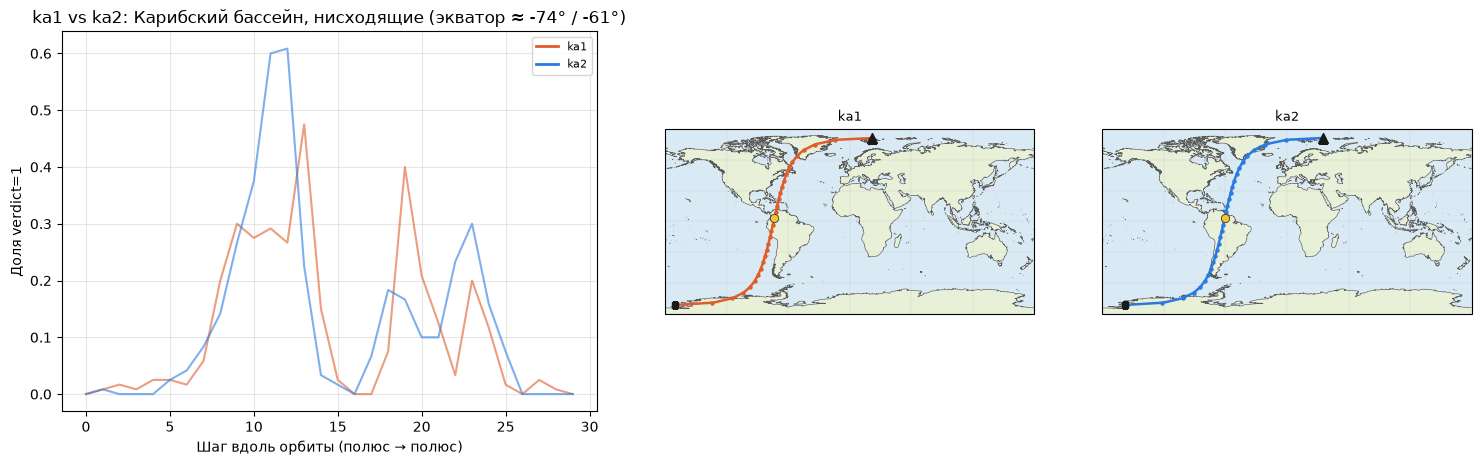

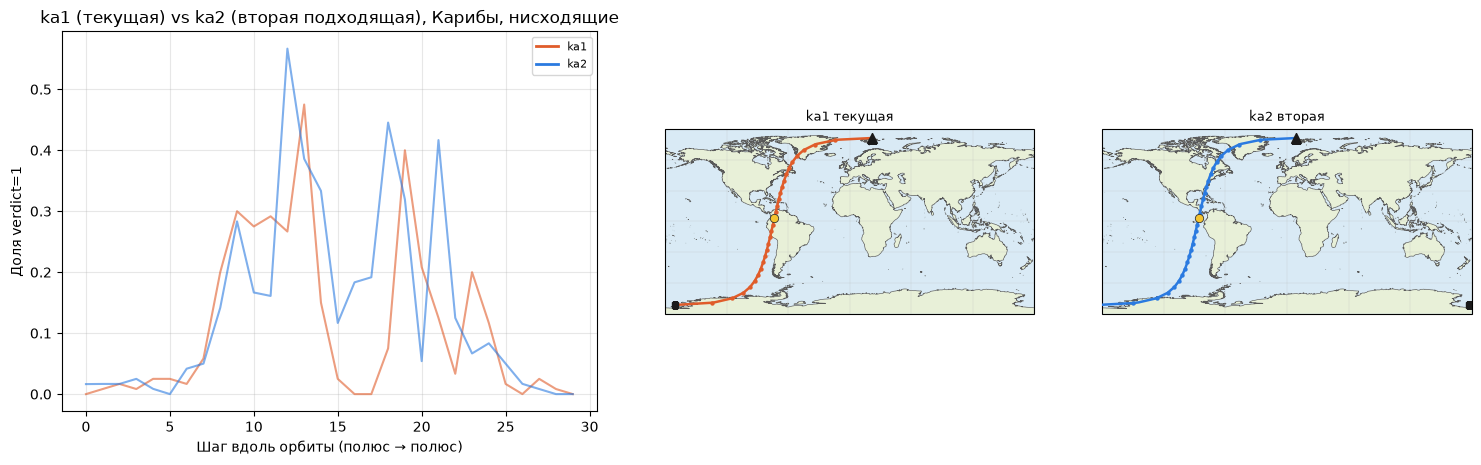

In [18]:
N_ADJACENT_KA = 1
START_IDX_KA_DESC = 286  # Карибский бассейн, нисходящие, 2025-02-12.
                         # Экватор ka1 ≈ -74°, ka2 ≈ -61° — оба внутри рамки
                         # 0…25°N / -90…-60°E.
pairs_sel = pairs_desc[START_IDX_KA_DESC:START_IDX_KA_DESC + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2, want_ascending=False))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title='ka1 vs ka2: Карибский бассейн, нисходящие (экватор ≈ -74° / -61°)',
)

p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), Карибы, нисходящие',
)


,ka1,ka2
предыдущий нисходящий,"2025-01-28 23:43:56 .. 00:34:34широта 81.3° → -81.3°, долгота 45.9° → -146.5°","2025-01-28 22:53:39 .. 23:44:16широта 81.3° → -81.3°, долгота 58.4° → -133.8°"
предыдущий восходящий,"2025-01-29 00:34:34 .. 01:25:13широта -81.3° → 81.3°, долгота -146.5° → 20.5°","2025-01-28 23:44:16 .. 00:34:55широта -81.3° → 81.3°, долгота -133.8° → 33.4°"
текущая,"2025-01-29 01:25:13 .. 02:15:51широта 81.3° → -81.3°, долгота 20.5° → -171.9°","2025-01-29 00:34:55 .. 01:25:33широта 81.3° → -81.3°, долгота 33.4° → -159.3°"
следующий восходящий,"2025-01-29 02:15:51 .. 03:06:30широта -81.3° → 81.3°, долгота -171.9° → -4.9°","2025-01-29 01:25:33 .. 02:16:12широта -81.3° → 81.3°, долгота -159.3° → 8.0°"
следующий нисходящий,"2025-01-29 03:06:30 .. 03:57:08широта 81.3° → -81.3°, долгота -4.9° → 162.7°","2025-01-29 02:16:12 .. 03:06:50широта 81.3° → -81.3°, долгота 8.0° → 175.3°"


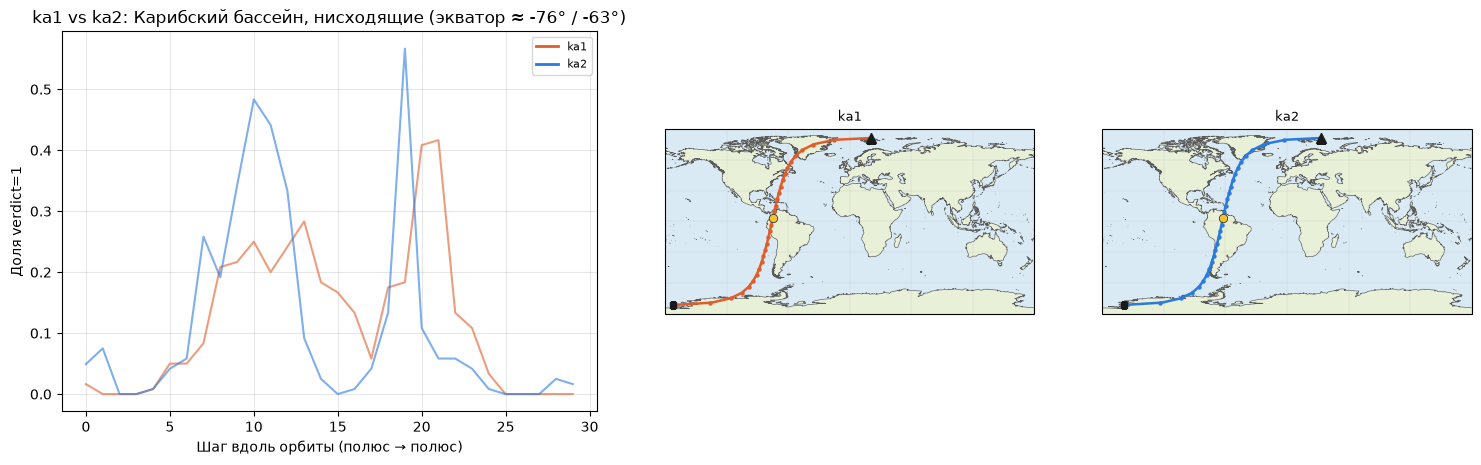

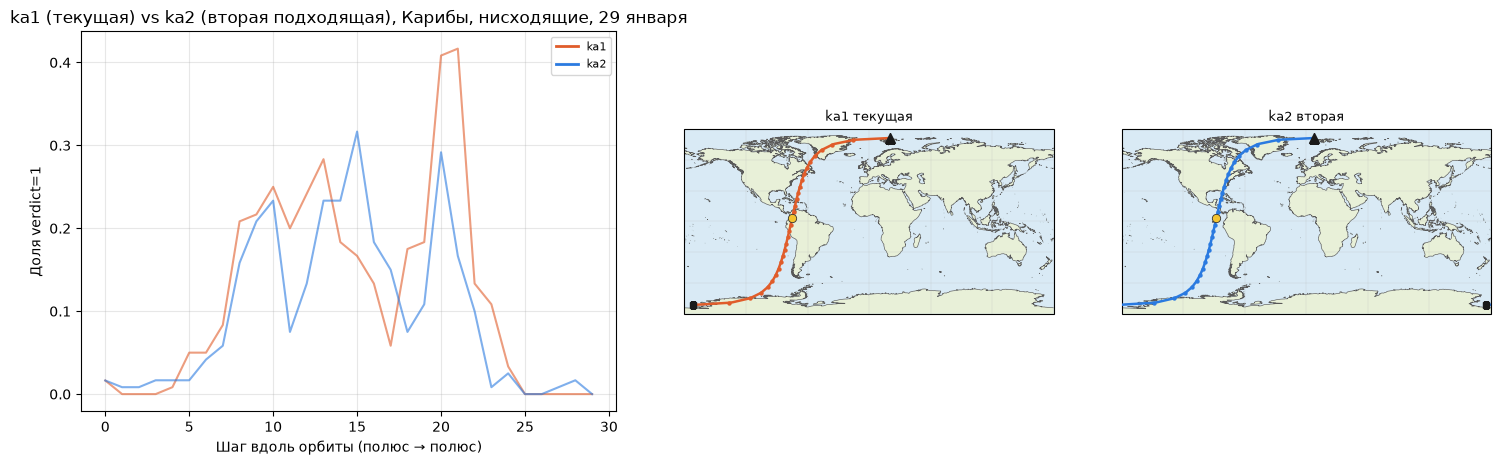

In [27]:
N_ADJACENT_KA = 1
START_IDX_KA_DESC = 106  # Карибский бассейн, нисходящие, 2025-01-29.
                         # Экватор ka1 ≈ -76°, ka2 ≈ -63° — оба внутри рамки
                         # 0…25°N / -90…-60°E.
pairs_sel = pairs_desc[START_IDX_KA_DESC:START_IDX_KA_DESC + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2, want_ascending=False))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title='ka1 vs ka2: Карибский бассейн, нисходящие (экватор ≈ -76° / -63°)',
)

p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), Карибы, нисходящие, 29 января',
)


,ka1,ka2
предыдущий нисходящий,"2025-01-22 19:11:24 .. 20:02:04широта 81.3° → -81.3°, долгота 114.2° → -78.9°","2025-01-22 18:21:08 .. 19:11:47широта 81.3° → -81.3°, долгота 126.4° → -66.7°"
предыдущий восходящий,"2025-01-22 20:02:04 .. 20:52:42широта -81.3° → 81.3°, долгота -78.9° → 88.4°","2025-01-22 19:11:47 .. 20:02:26широта -81.3° → 81.3°, долгота -66.7° → 100.5°"
текущая,"2025-01-22 20:52:42 .. 21:43:20широта 81.3° → -81.3°, долгота 88.4° → -104.0°","2025-01-22 20:02:26 .. 20:53:02широта 81.3° → -81.3°, долгота 100.5° → -91.2°"
следующий восходящий,"2025-01-22 21:43:20 .. 22:33:58широта -81.3° → 81.3°, долгота -104.0° → 63.3°","2025-01-22 20:53:02 .. 21:43:40широта -81.3° → 81.3°, долгота -91.2° → 76.5°"
следующий нисходящий,"2025-01-22 22:33:58 .. 23:24:36широта 81.3° → -81.3°, долгота 63.3° → -129.1°","2025-01-22 21:43:40 .. 22:34:19широта 81.3° → -81.3°, долгота 76.5° → -116.6°"


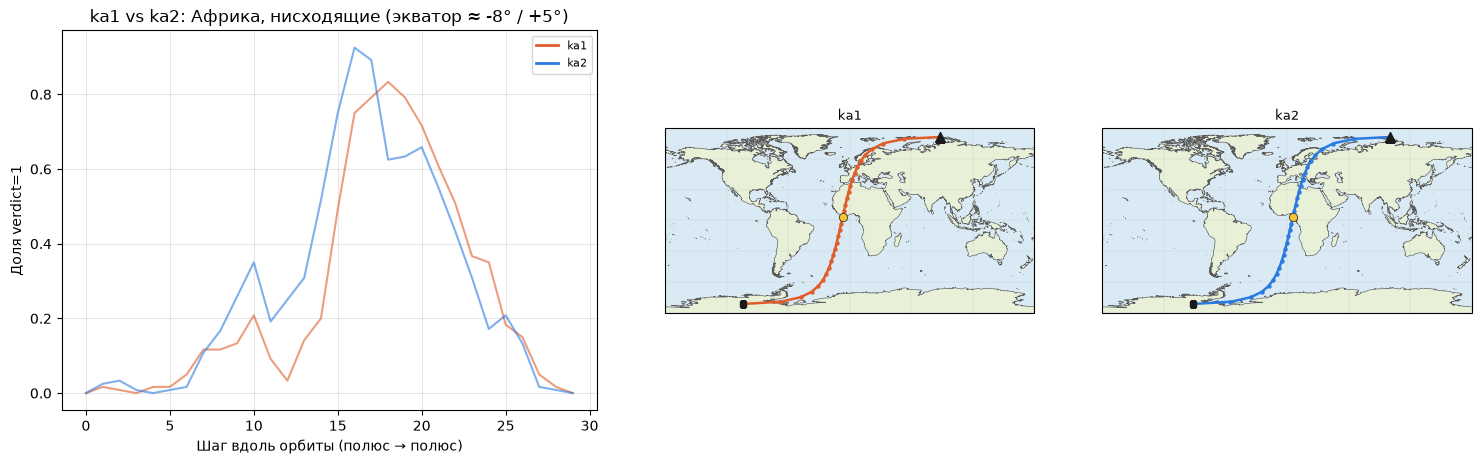

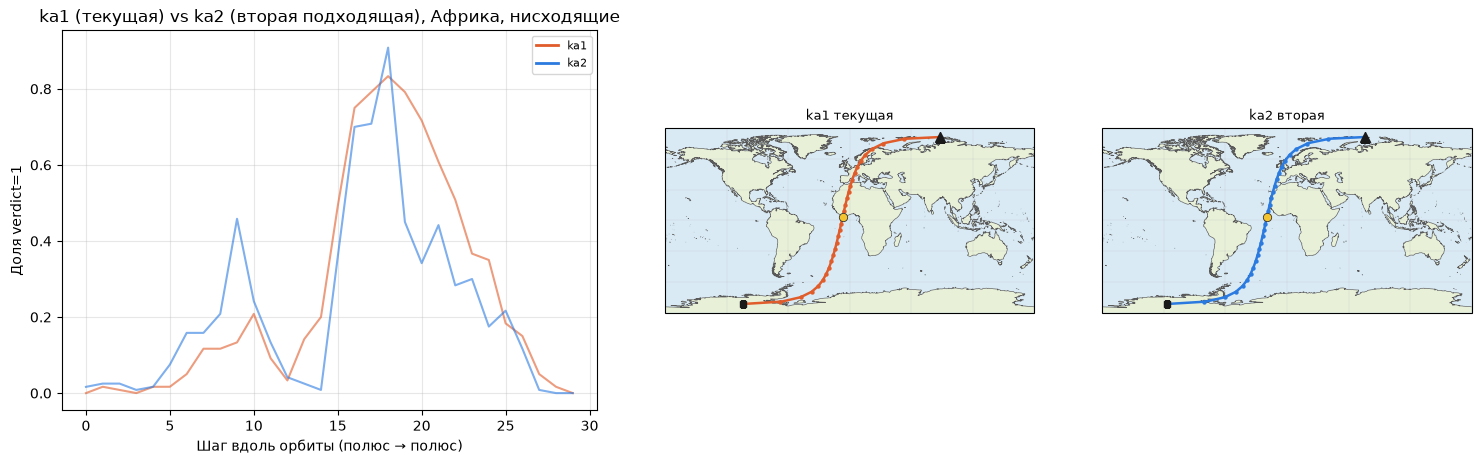

In [19]:
N_ADJACENT_KA = 1
START_IDX_KA_DESC = 24  # Африка / Гвинейский залив, нисходящие, 2025-01-22.
                        # Экватор ka1 ≈ -8°, ka2 ≈ +5°.
pairs_sel = pairs_desc[START_IDX_KA_DESC:START_IDX_KA_DESC + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2, want_ascending=False))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title='ka1 vs ka2: Африка, нисходящие (экватор ≈ -8° / +5°)',
)

p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), Африка, нисходящие',
)


,ka1,ka2
предыдущий восходящий,"2025-02-03 12:14:17 .. 13:04:56широта -81.3° → 81.3°, долгота 39.1° → -153.9°","2025-02-03 11:24:52 .. 12:14:40широта -80.7° → 81.3°, долгота 31.6° → -142.0°"
предыдущий нисходящий,"2025-02-03 13:04:56 .. 13:55:35широта 81.3° → -81.3°, долгота -153.9° → 13.2°","2025-02-03 12:14:40 .. 13:05:16широта 81.3° → -81.3°, долгота -142.0° → 26.3°"
текущая,"2025-02-03 13:55:35 .. 14:46:14широта -81.3° → 81.3°, долгота 13.2° → -180.0°","2025-02-03 13:05:16 .. 13:55:55широта -81.3° → 81.3°, долгота 26.3° → -166.5°"
следующий нисходящий,"2025-02-03 14:46:14 .. 15:36:53широта 81.3° → -81.3°, долгота -180.0° → -12.8°","2025-02-03 13:55:55 .. 14:46:34широта 81.3° → -81.3°, долгота -166.5° → 0.4°"
следующий восходящий,"2025-02-03 15:36:53 .. 16:27:31широта -81.3° → 81.3°, долгота -12.8° → 154.6°","2025-02-03 14:46:34 .. 15:37:13широта -81.3° → 81.3°, долгота 0.4° → 167.5°"


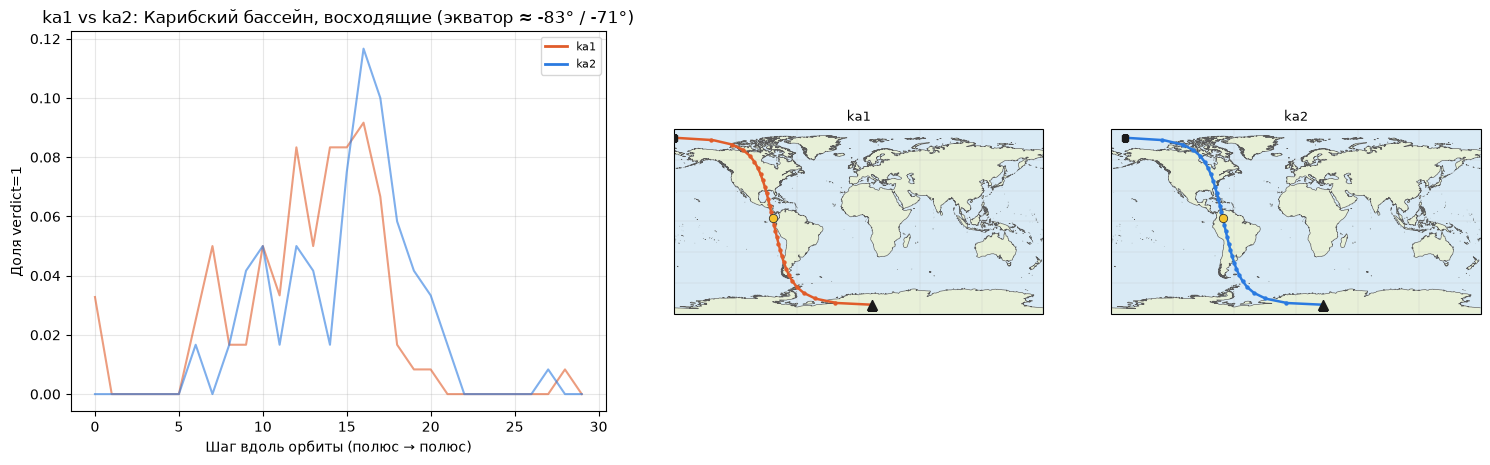

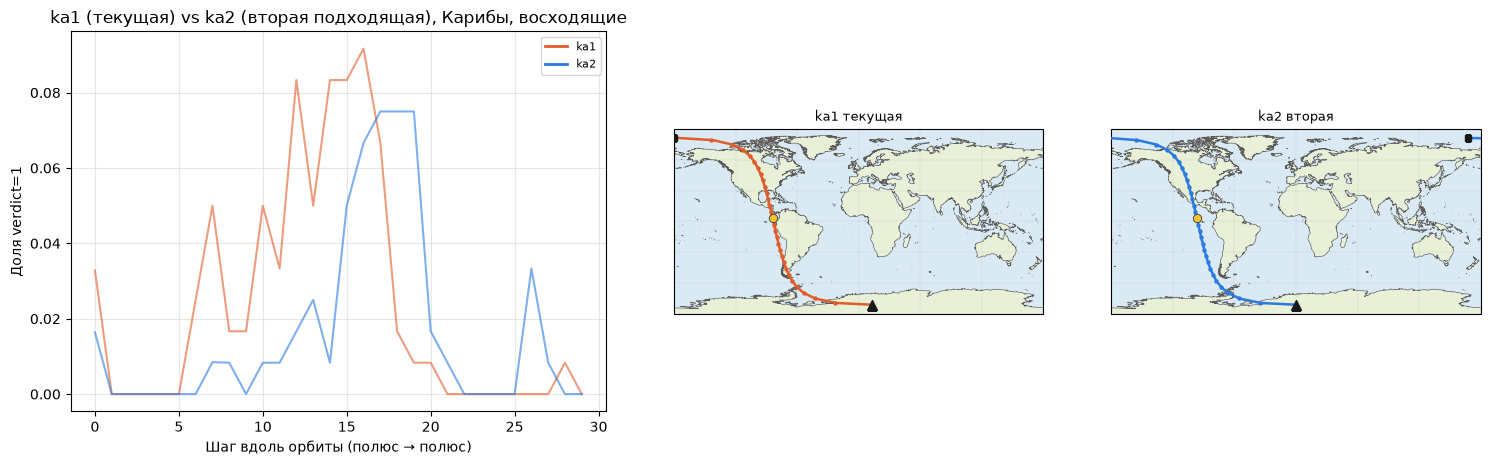

In [20]:
N_ADJACENT_KA = 1
START_IDX_KA = 186  # Карибский бассейн, восходящие, 2025-02-03.
                    # Экватор ka1 ≈ -83°, ka2 ≈ -71° — оба внутри той же рамки,
                    # что в п.3.
pairs_sel = pairs[START_IDX_KA:START_IDX_KA + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title='ka1 vs ka2: Карибский бассейн, восходящие (экватор ≈ -83° / -71°)',
)

p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), Карибы, восходящие',
)


,ka1,ka2
предыдущий восходящий,"2025-01-31 11:39:20 .. 12:29:58широта -81.3° → 81.3°, долгота 47.1° → -145.4°","2025-01-31 10:49:14 .. 11:39:41широта -81.2° → 81.3°, долгота 55.0° → -133.1°"
предыдущий нисходящий,"2025-01-31 12:29:58 .. 13:20:36широта 81.3° → -81.3°, долгота -145.4° → 22.1°","2025-01-31 11:39:41 .. 12:30:18широта 81.3° → -81.3°, долгота -133.1° → 34.7°"
текущая,"2025-01-31 13:20:36 .. 14:11:15широта -81.3° → 81.3°, долгота 22.1° → -170.9°","2025-01-31 12:30:18 .. 13:20:57широта -81.3° → 81.3°, долгота 34.7° → -158.0°"
следующий нисходящий,"2025-01-31 14:11:15 .. 15:01:54широта 81.3° → -81.3°, долгота -170.9° → -3.8°","2025-01-31 13:20:57 .. 14:11:35широта 81.3° → -81.3°, долгота -158.0° → 9.3°"
следующий восходящий,"2025-01-31 15:01:54 .. 15:52:33широта -81.3° → 81.3°, долгота -3.8° → 163.1°","2025-01-31 14:11:35 .. 15:02:14широта -81.3° → 81.3°, долгота 9.3° → 176.5°"


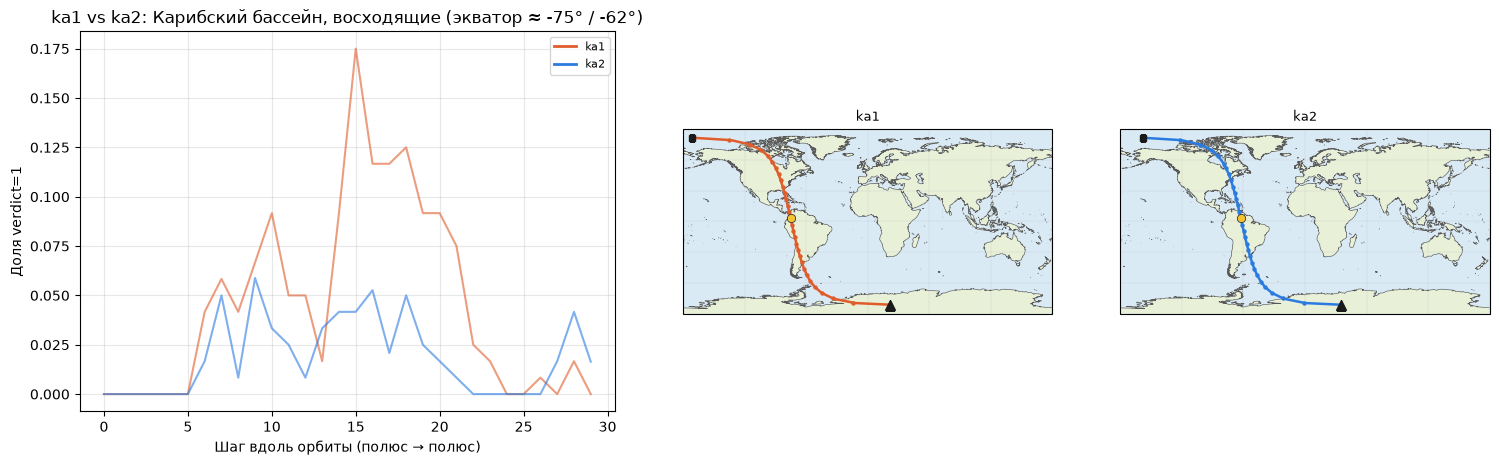

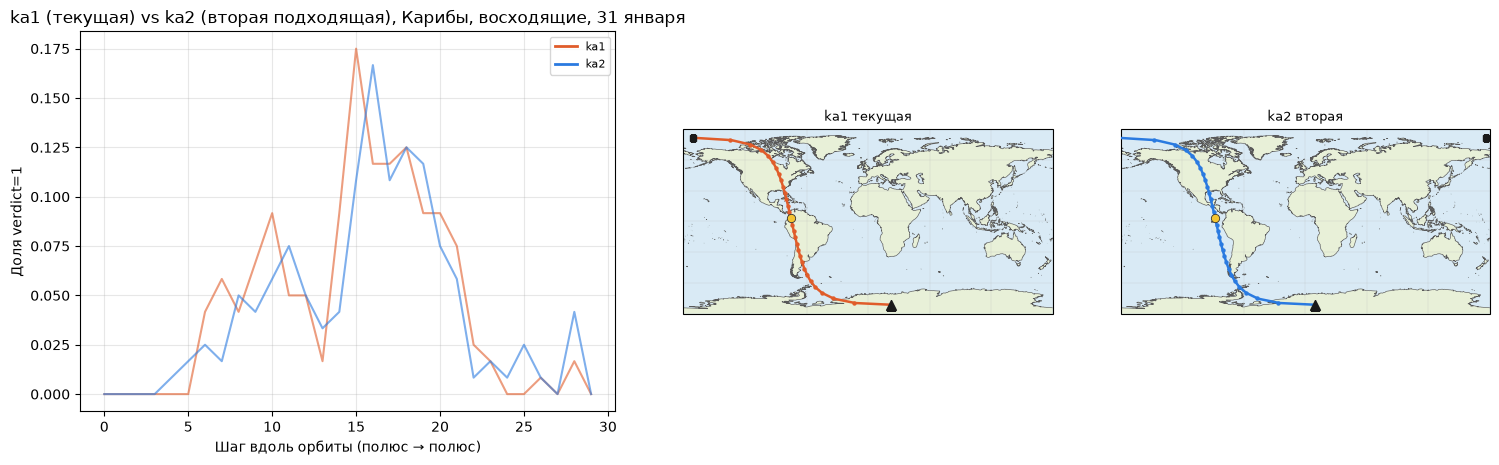

In [28]:
N_ADJACENT_KA = 1
START_IDX_KA = 143  # Карибский бассейн, восходящие, 2025-01-31.
                    # Экватор ka1 ≈ -75°, ka2 ≈ -62°.
pairs_sel = pairs[START_IDX_KA:START_IDX_KA + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title='ka1 vs ka2: Карибский бассейн, восходящие (экватор ≈ -75° / -62°)',
)

p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), Карибы, восходящие, 31 января',
)


,ka1,ka2
предыдущий восходящий,"2025-01-26 05:03:26 .. 05:54:04широта -81.3° → 81.3°, долгота 146.0° → -46.6°","2025-01-25 21:28:02 .. 22:18:40широта -81.3° → 81.3°, долгота -100.4° → 67.1°"
предыдущий нисходящий,"2025-01-26 05:54:04 .. 06:44:43широта 81.3° → -81.3°, долгота -46.6° → 120.6°","2025-01-26 05:03:47 .. 05:54:24широта 81.3° → -81.3°, долгота -34.1° → 133.6°"
текущая,"2025-01-26 06:44:43 .. 07:35:21широта -81.3° → 81.3°, долгота 120.6° → -72.1°","2025-01-26 05:54:24 .. 06:45:04широта -81.3° → 81.3°, долгота 133.6° → -59.6°"
следующий нисходящий,"2025-01-26 07:35:21 .. 08:25:59широта 81.3° → -81.3°, долгота -72.1° → 95.5°","2025-01-26 06:45:04 .. 07:35:41широта 81.3° → -81.3°, долгота -59.6° → 108.2°"
следующий восходящий,"2025-01-26 08:25:59 .. 09:16:38широта -81.3° → 81.3°, долгота 95.5° → -97.5°","2025-01-26 07:35:41 .. 08:26:20широта -81.3° → 81.3°, долгота 108.2° → -84.6°"


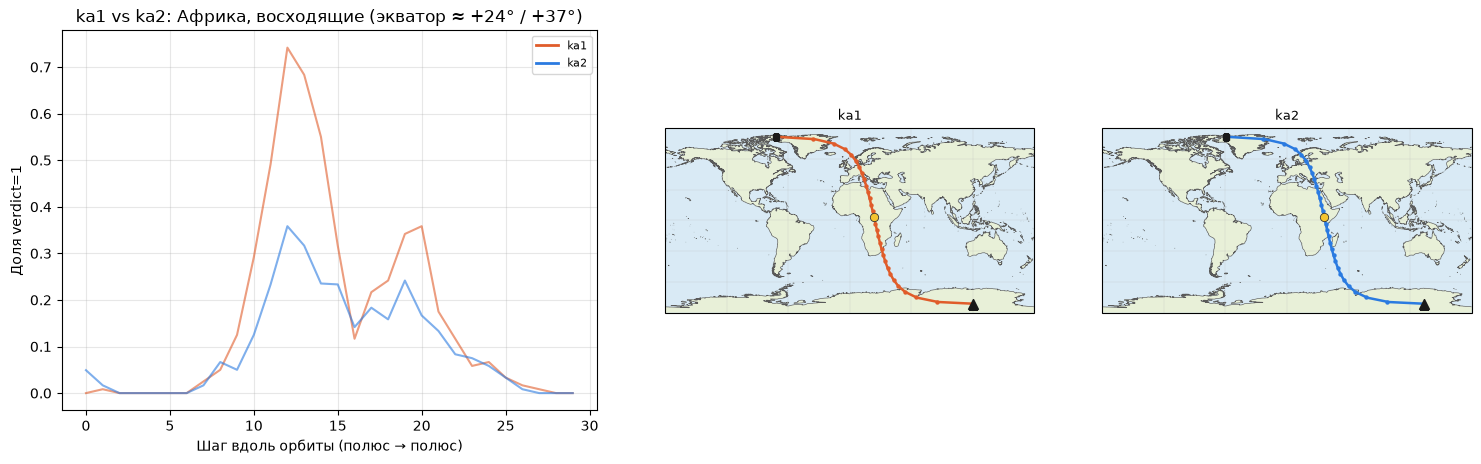

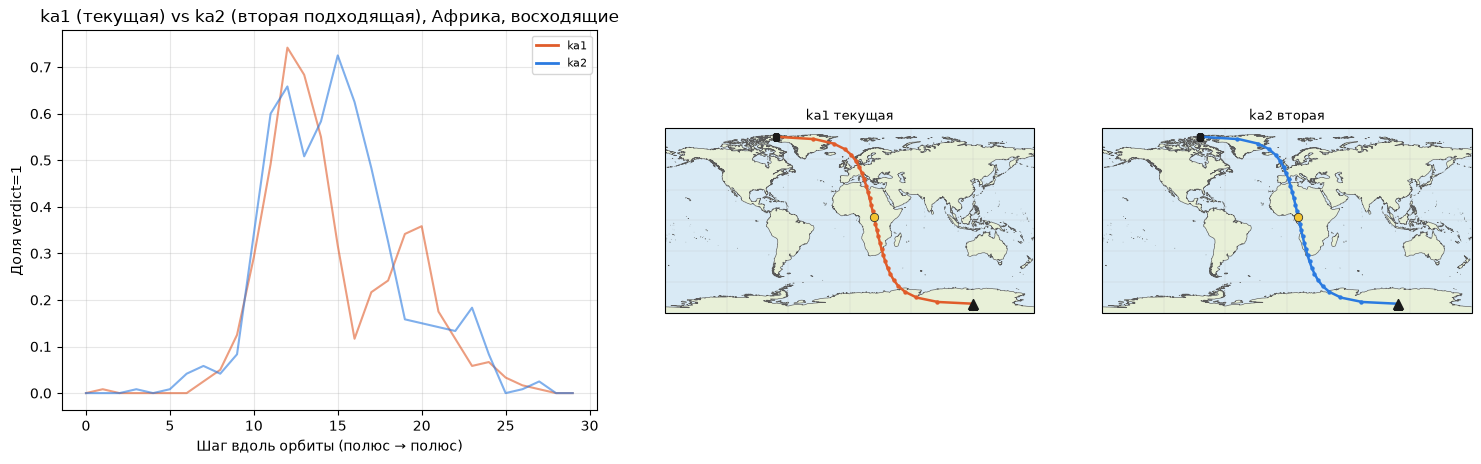

In [21]:
N_ADJACENT_KA = 1
START_IDX_KA = 72  # Центральная Африка, восходящие, 2025-01-26.
                   # Экватор ka1 ≈ +24°, ka2 ≈ +37°.
pairs_sel = pairs[START_IDX_KA:START_IDX_KA + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p1, p2))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1'), (p2, '#2a7ae0', 'ka2')],
    title='ka1 vs ka2: Африка, восходящие (экватор ≈ +24° / +37°)',
)

p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p1, '#e05c2a', 'ka1 текущая'), (second_p, '#2a7ae0', 'ka2 вторая')],
    title='ka1 (текущая) vs ka2 (вторая подходящая), Африка, восходящие',
)


## 9. Та же пара, текущей считается ka2

Тот же восходящий пример, что индекс 94 в п.7 (27 января, Тихий океан). В таблицу и на рисунок пара передаётся в обратном порядке: текущая полуорбита — ka2, вторая подходящая ищется среди соседних восходящих ka1. Так видно то же сопоставление, если начинать с другого аппарата.


,ka2,ka1
предыдущий восходящий,"2025-01-27 20:43:49 .. 21:34:28широта -81.3° → 81.3°, долгота -88.9° → 78.3°","2025-01-27 21:34:07 .. 22:24:45широта -81.3° → 81.3°, долгота -101.5° → 65.8°"
предыдущий нисходящий,"2025-01-27 21:34:28 .. 22:25:05широта 81.3° → -81.3°, долгота 78.3° → -114.0°","2025-01-27 22:24:45 .. 23:15:24широта 81.3° → -81.3°, долгота 65.8° → -127.0°"
текущая,"2025-01-27 22:25:05 .. 23:15:45широта -81.3° → 81.3°, долгота -114.0° → 52.8°","2025-01-27 23:15:24 .. 00:06:02широта -81.3° → 81.3°, долгота -127.0° → 40.4°"
следующий нисходящий,"2025-01-27 23:15:45 .. 00:06:23широта 81.3° → -81.3°, долгота 52.8° → -139.8°","2025-01-28 00:06:02 .. 00:56:40широта 81.3° → -81.3°, долгота 40.4° → -152.0°"
следующий восходящий,"2025-01-28 00:06:23 .. 00:57:02широта -81.3° → 81.3°, долгота -139.8° → 27.4°","2025-01-28 00:56:40 .. 01:47:19широта -81.3° → 81.3°, долгота -152.0° → 14.9°"


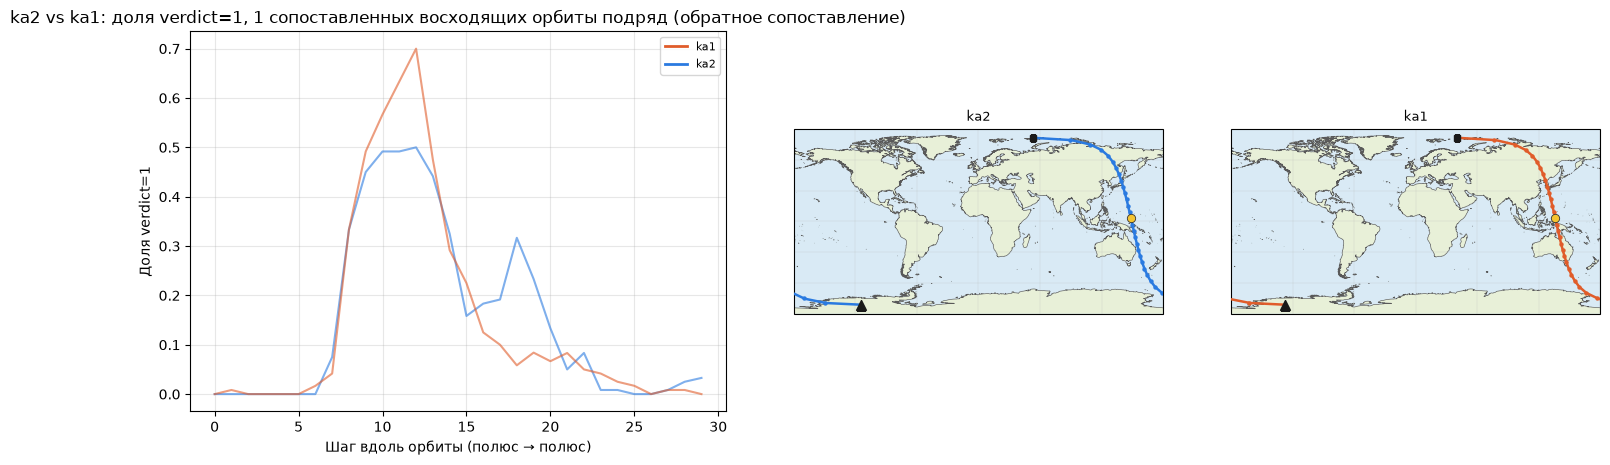

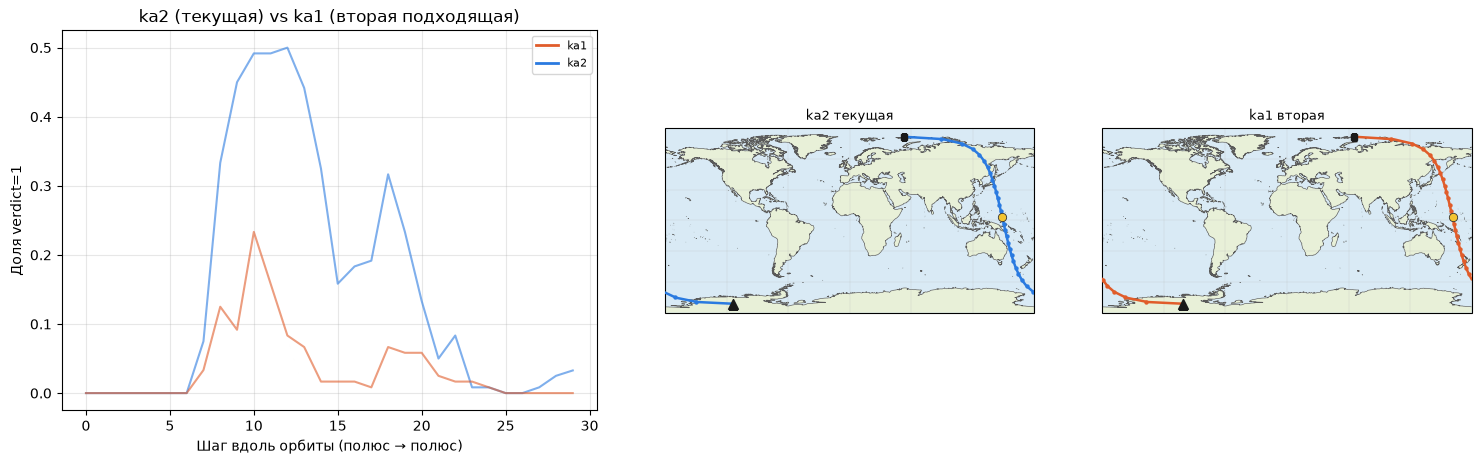

In [22]:
N_ADJACENT_KA = 1
START_IDX_KA_REV = 94  # та же физическая группа, что в п.7: 2025-01-27, Тихий океан.
                       # Роли переставлены: текущая орбита — ka2.
pairs_sel = pairs[START_IDX_KA_REV:START_IDX_KA_REV + N_ADJACENT_KA]

seconds_sel = []
for p1, p2 in pairs_sel:
    seconds_sel.append(_orbit_table(p2, p1, all_profiles_ka2, all_profiles,
                                     want_ascending=True, primary_name='ka2', secondary_name='ka1'))

p1, p2 = pairs_sel[0]
plot_verdict_pair_with_maps(
    [(p2, '#2a7ae0', 'ka2'), (p1, '#e05c2a', 'ka1')],
    title=f'ka2 vs ka1: доля verdict=1, {len(pairs_sel)} сопоставленных восходящих орбиты подряд (обратное сопоставление)',
)

# --- второй график: ka2 (текущая) vs ka1 (вторая подходящая) ---
p1, p2 = pairs_sel[0]
second_p = seconds_sel[0]
plot_verdict_pair_with_maps(
    [(p2, '#2a7ae0', 'ka2 текущая'), (second_p, '#e05c2a', 'ka1 вторая')],
    title='ka2 (текущая) vs ka1 (вторая подходящая)',
)

## 10. Все пары ka1 и ka2, не один пример

Пункты 7–9 показывают несколько выбранных пролётов. Здесь для каждой чистой полуорбиты ka1, и восходящей, и нисходящей, подбираются полуорбиты ka2 того же направления, если времена пересечения экватора отличаются не больше чем на час (`MAX_CONJ_DT_S`). Обычный сосед — около 50 минут. Пропуск телеметрии начинается примерно со 150 минут (три полупериода), и часовой порог его отсекает. У одной ka1 обычно одна или две такие полуорбиты ka2. Восходящие с нисходящими не смешиваются.

В печати ячейки такая полуорбита ka2 названа сопряжённой: имеется в виду совпадение по времени экватора.

Профили ka1 собраны в п.3 (`all_profiles`), профили ka2 — в п.7 (`all_profiles_ka2`).

Первая ячейка считает, насколько похожи профили `verdict` пары: Пирсон (`r`), Спирмен (`ρ`), `r²`, RMSE и MAE. В сводке — медиана по всем парам, ниже — таблица по каждой полуорбите ka1. Вторая ячейка рисует шесть случайных строк (зерно `CONJ_EXAMPLE_SEED = 7`): поровну восходящих и нисходящих, на графике только доля свистов.


In [23]:
from IPython.display import HTML, display

MAX_CONJ_DT_S = 3600  # час; норма ~50 мин, дыры начинаются с ~152 мин (см. проверку на 30 сутках)


def verdict_pair_metrics(y1, y2):
    """Форма: r (Пирсон), ρ (Спирмен), r². Амплитуда: RMSE, MAE. NaN-шаги выкидываются."""
    a = np.asarray(y1, dtype=np.float64)
    b = np.asarray(y2, dtype=np.float64)
    if a.shape != b.shape:
        raise ValueError(f'разной длины профили: {a.shape} vs {b.shape}')
    ok = np.isfinite(a) & np.isfinite(b)
    n = int(ok.sum())
    out = {'n': n, 'n_all': int(a.size), 'r': np.nan, 'rho': np.nan, 'r2': np.nan,
           'rmse': np.nan, 'mae': np.nan}
    if n == 0:
        return out
    a, b = a[ok], b[ok]
    d = a - b
    out['mae'] = float(np.mean(np.abs(d)))
    out['rmse'] = float(np.sqrt(np.mean(d * d)))
    if n >= 2 and float(np.std(a)) > 0 and float(np.std(b)) > 0:
        r = float(np.corrcoef(a, b)[0, 1])
        out['r'] = r
        out['r2'] = r * r
        out['rho'] = float(pd.Series(a).corr(pd.Series(b), method='spearman'))
    return out


def attach_verdict_metrics(conjugates):
    n_pairs = 0
    for c in conjugates:
        v1 = c['ka1']['verdict']
        for m in c['ka2']:
            m['metrics'] = verdict_pair_metrics(v1, m['profile']['verdict'])
            n_pairs += 1
    return n_pairs


def _t_eq(p):
    return p['t'][np.nanargmin(np.abs(p['lat']))]


def _is_ascending(p):
    return p['lat'][0] < p['lat'][-1]


def conjugate_half_orbits(primary_profs, secondary_profs, max_dt_s=MAX_CONJ_DT_S):
    """Для каждой полуорбиты primary — secondary того же направления с |Δt_eq| ≤ max_dt_s.

    Кандидаты сортируются по |dt| (ближайшие первыми). Возвращает список словарей:
    ka1, ascending, t_eq, ka2=[{profile, dt_s}, ...].
    """
    sec_asc = [p for p in secondary_profs if _is_ascending(p)]
    sec_desc = [p for p in secondary_profs if not _is_ascending(p)]
    t_asc = np.array([_t_eq(p) for p in sec_asc], dtype=np.float64)
    t_desc = np.array([_t_eq(p) for p in sec_desc], dtype=np.float64)
    out = []
    for p1 in primary_profs:
        want_asc = _is_ascending(p1)
        pool, t_pool = (sec_asc, t_asc) if want_asc else (sec_desc, t_desc)
        t1 = float(_t_eq(p1))
        if len(t_pool) == 0:
            mates = []
        else:
            dts = t_pool - t1
            keep = np.flatnonzero(np.abs(dts) <= max_dt_s)
            order = keep[np.argsort(np.abs(dts[keep]))]
            mates = [{'profile': pool[int(j)], 'dt_s': float(dts[j])} for j in order]
        out.append({'ka1': p1, 'ascending': want_asc, 't_eq': t1, 'ka2': mates})
    return out


conjugates_ka1 = conjugate_half_orbits(all_profiles, all_profiles_ka2)
n_pairs = attach_verdict_metrics(conjugates_ka1)

n_mates = np.array([len(c['ka2']) for c in conjugates_ka1])
n_asc = sum(c['ascending'] for c in conjugates_ka1)
n_desc = len(conjugates_ka1) - n_asc
print(f'полуорбит ka1: {len(conjugates_ka1)} (восходящих {n_asc}, нисходящих {n_desc})')
print('число сопряжённых ka2 на одну ka1:')
for k in range(int(n_mates.max()) + 1 if len(n_mates) else 1):
    print(f'  {k} ka2: {int(np.sum(n_mates == k))}')

_all_dt = np.array([m['dt_s'] for c in conjugates_ka1 for m in c['ka2']])
if len(_all_dt):
    print(f'|dt| сопряжений: n={len(_all_dt)}, медиана={np.median(np.abs(_all_dt))/60:.1f} мин, '
          f'мин={np.min(np.abs(_all_dt))/60:.1f}, макс={np.max(np.abs(_all_dt))/60:.1f}')
    print(f'из них |dt|>60 мин (не должно быть при пороге {MAX_CONJ_DT_S}с): '
          f'{int(np.sum(np.abs(_all_dt) > MAX_CONJ_DT_S))}')

_mets = [m['metrics'] for c in conjugates_ka1 for m in c['ka2']]
if _mets:
    def _med(key):
        v = np.array([x[key] for x in _mets], dtype=np.float64)
        v = v[np.isfinite(v)]
        return float(np.median(v)) if v.size else np.nan
    _n_gap = sum(x['n'] < x['n_all'] for x in _mets)
    print(f'пары ka1–ka2: {n_pairs}; из них с пропусками шагов: {_n_gap}')
    print(f'медиана по парам (форма): r={_med("r"):.3f}, ρ={_med("rho"):.3f}, r²={_med("r2"):.3f}; '
          f'амплитуда RMSE={_med("rmse"):.3f}, MAE={_med("mae"):.3f} '
          f'(n шагов медиана={_med("n"):.0f} из {N_STEPS})')

rows = []
for c in conjugates_ka1:
    t1 = pd.Timestamp(int(c['t_eq']), unit='s', tz='UTC')
    dts = ', '.join(f'{m["dt_s"]/60:+.1f}' for m in c['ka2']) or '—'
    rs = ', '.join(f'{m["metrics"]["r"]:.2f}' if np.isfinite(m['metrics']['r']) else '—' for m in c['ka2']) or '—'
    rhos = ', '.join(f'{m["metrics"]["rho"]:.2f}' if np.isfinite(m['metrics']['rho']) else '—' for m in c['ka2']) or '—'
    rows.append({
        'направление': 'восходящая' if c['ascending'] else 'нисходящая',
        'ka1 экватор (UTC)': t1.strftime('%Y-%m-%d %H:%M:%S'),
        'n ka2': len(c['ka2']),
        'dt ka2−ka1 (мин)': dts,
        'r': rs,
        'ρ': rhos,
    })
df_conj = pd.DataFrame(rows)
display(df_conj)
print('полный список в conjugates_ka1 (профили) и df_conj (таблица).')


полуорбит ka1: 753 (восходящих 379, нисходящих 374)
число сопряжённых ka2 на одну ka1:
  0 ka2: 34
  1 ka2: 88
  2 ka2: 631
|dt| сопряжений: n=1350, медиана=50.5 мин, мин=31.1, макс=59.0
из них |dt|>60 мин (не должно быть при пороге 3600с): 0
пары ka1–ka2: 1350; из них с пропусками шагов: 447
медиана по парам (форма): r=0.761, ρ=0.796, r²=0.580; амплитуда RMSE=0.078, MAE=0.049 (n шагов медиана=30 из 30)


,направление,ka1 экватор (UTC),n ka2,dt ka2−ka1 (мин),r,ρ
0,восходящая,2025-01-20 17:49:53,1,+51.0,0.45,0.34
1,нисходящая,2025-01-20 18:38:47,1,+51.0,0.93,0.93
2,восходящая,2025-01-20 19:31:09,2,"-50.3, +51.0","0.34, 0.91","0.59, 0.90"
3,нисходящая,2025-01-20 20:20:02,2,"-50.3, +51.0","0.96, 0.85","0.96, 0.89"
4,восходящая,2025-01-20 21:12:25,2,"-50.3, +51.0","0.40, 0.75","0.74, 0.87"
...,...,...,...,...,...,...
748,восходящая,2025-02-18 15:35:19,2,"-50.3, +51.0","0.28, 0.66","0.36, 0.71"
749,нисходящая,2025-02-18 16:24:12,2,"-48.5, +51.0","0.84, 0.90","0.77, 0.82"
750,восходящая,2025-02-18 17:16:35,2,"-50.3, +51.0","0.49, 0.40","0.55, 0.51"
751,нисходящая,2025-02-18 18:05:30,2,"-50.3, +50.8","0.70, 0.87","0.78, 0.77"


полный список в conjugates_ka1 (профили) и df_conj (таблица).


примеры индексов ka1 (из 753): [182, 476, 517, 590, 632, 710]


,направление,ka1 экватор (UTC),n ka2,dt ka2−ka1 (мин),r,ρ
182,нисходящая,2025-01-27 19:26:39,2,"-50.3, +51.0","0.90, 0.95","0.88, 0.94"
476,восходящая,2025-02-07 11:12:05,2,"-50.3, +51.0","0.85, 0.85","0.86, 0.75"
517,восходящая,2025-02-09 05:24:03,1,-51.8,0.88,0.91
590,нисходящая,2025-02-12 15:15:58,2,"+49.3, -51.9","0.79, 0.86","0.82, 0.85"
632,нисходящая,2025-02-14 11:07:32,2,"-50.3, +51.0","0.82, 0.91","0.87, 0.85"
710,восходящая,2025-02-17 07:31:01,2,"-50.5, +51.0","0.66, 0.93","0.91, 0.90"



--- ka1[182] нисходящая, экватор 2025-01-27 19:26:39 UTC, 2 ka2 ---


ka1 нисходящая,ka2 #1 (dt=-50.3 мин),ka2 #2 (dt=+51.0 мин)
"2025-01-27 19:02:12 .. 19:52:51широта 81.3° → -81.3°, долгота 116.3° → -76.5°","2025-01-27 18:11:54 .. 19:02:33широта 81.3° → -81.3°, долгота 129.2° → -63.9°","2025-01-27 19:53:11 .. 20:43:49широта 81.3° → -81.3°, долгота 103.7° → -88.9°"


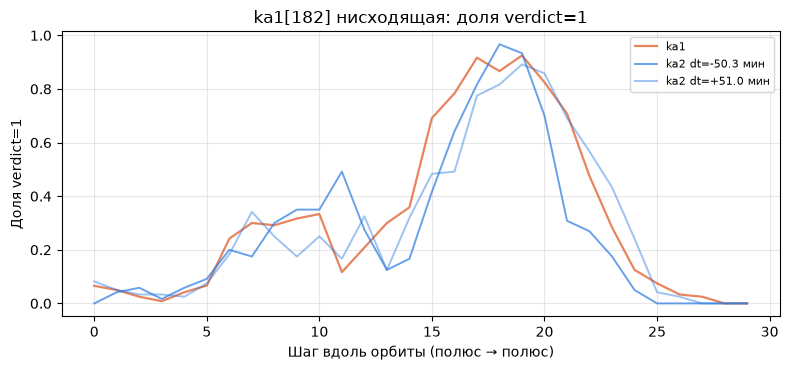

,dt (мин),n шагов,r,ρ,r²,RMSE,MAE
ka2,,,,,,,
1,-50.3,30 из 30,0.902,0.877,0.814,0.141,0.095
2,+51.0,30 из 30,0.952,0.944,0.906,0.097,0.067



--- ka1[476] восходящая, экватор 2025-02-07 11:12:05 UTC, 2 ka2 ---


ka1 восходящая,ka2 #1 (dt=-50.3 мин),ka2 #2 (dt=+51.0 мин)
"2025-02-07 10:45:54 .. 11:36:33широта -81.3° → 81.3°, долгота 60.6° → -132.4°","2025-02-07 09:55:38 .. 10:46:14широта -81.3° → 81.3°, долгота 72.5° → -118.9°","2025-02-07 11:36:52 .. 12:27:32широта -81.3° → 81.3°, долгота 48.4° → -144.8°"


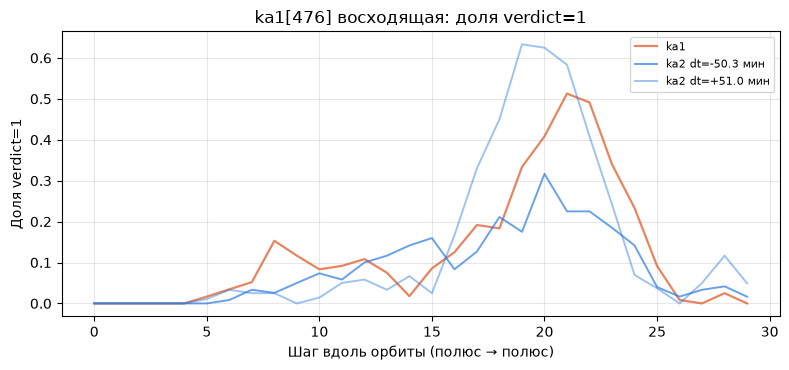

,dt (мин),n шагов,r,ρ,r²,RMSE,MAE
ka2,,,,,,,
1,-50.3,30 из 30,0.850,0.856,0.723,0.096,0.062
2,+51.0,30 из 30,0.851,0.754,0.724,0.107,0.074



--- ka1[517] восходящая, экватор 2025-02-09 05:24:03 UTC, 1 ka2 ---


ka1 восходящая,ka2 #1 (dt=-51.8 мин)
"2025-02-09 04:57:53 .. 05:48:30широта -81.3° → 81.3°, долгота 147.1° → -45.0°","2025-02-09 04:08:08 .. 04:58:12широта -81.0° → 81.3°, долгота 147.1° → -32.1°"


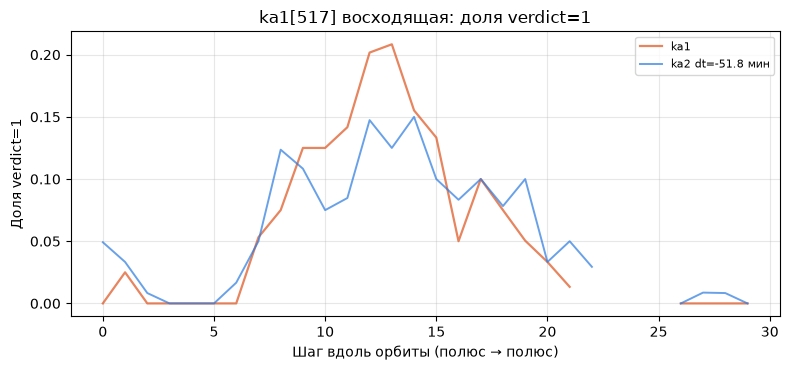

,dt (мин),n шагов,r,ρ,r²,RMSE,MAE
ka2,,,,,,,
1,-51.8,26 из 30,0.884,0.911,0.781,0.032,0.022



--- ka1[590] нисходящая, экватор 2025-02-12 15:15:58 UTC, 2 ka2 ---


ka1 нисходящая,ka2 #1 (dt=+49.3 мин),ka2 #2 (dt=-51.9 мин)
"2025-02-12 14:49:41 .. 15:40:30широта 81.2° → -81.3°, долгота -176.4° → -13.2°","2025-02-12 15:40:51 .. 16:31:29широта 81.3° → -81.3°, долгота 166.9° → -25.7°","2025-02-12 13:59:35 .. 14:50:13широта 81.3° → -81.3°, долгота -168.1° → -0.6°"


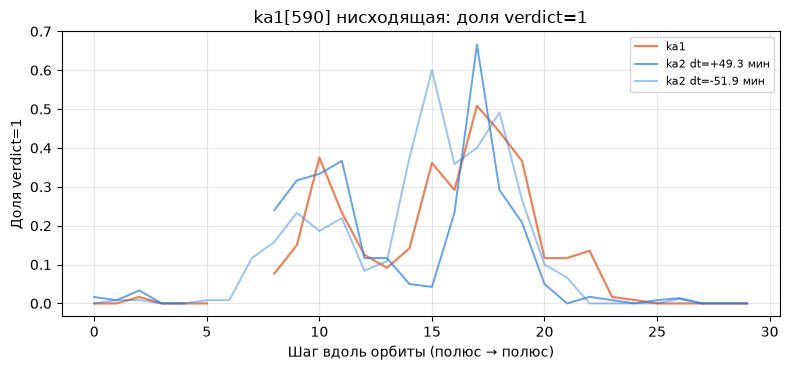

,dt (мин),n шагов,r,ρ,r²,RMSE,MAE
ka2,,,,,,,
1,+49.3,27 из 30,0.788,0.821,0.620,0.104,0.069
2,-51.9,28 из 30,0.860,0.847,0.740,0.087,0.053



--- ka1[632] нисходящая, экватор 2025-02-14 11:07:32 UTC, 2 ka2 ---


ka1 нисходящая,ka2 #1 (dt=-50.3 мин),ka2 #2 (dt=+51.0 мин)
"2025-02-14 10:43:05 .. 11:33:44широта 81.3° → -81.3°, долгота -118.6° → 48.4°","2025-02-14 09:52:49 .. 10:43:26широта 81.3° → -81.3°, долгота -106.3° → 61.4°","2025-02-14 11:34:05 .. 12:24:42широта 81.3° → -81.3°, долгота -131.4° → 36.4°"


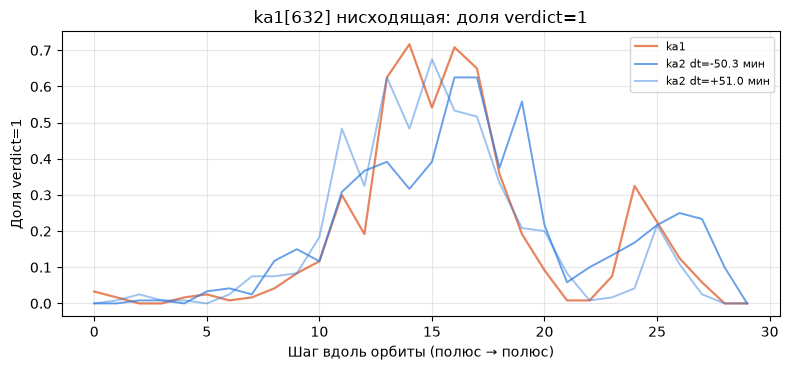

,dt (мин),n шагов,r,ρ,r²,RMSE,MAE
ka2,,,,,,,
1,-50.3,30 из 30,0.818,0.868,0.669,0.133,0.087
2,+51.0,30 из 30,0.906,0.851,0.821,0.098,0.063



--- ka1[710] восходящая, экватор 2025-02-17 07:31:01 UTC, 2 ka2 ---


ka1 восходящая,ka2 #1 (dt=-50.5 мин),ka2 #2 (dt=+51.0 мин)
"2025-02-17 07:04:50 .. 07:55:29широта -81.3° → 81.3°, долгота 116.3° → -76.6°","2025-02-17 06:14:07 .. 07:05:12широта -81.1° → 81.3°, долгота 139.0° → -63.9°","2025-02-17 07:55:50 .. 08:46:29широта -81.3° → 81.3°, долгота 103.5° → -89.3°"


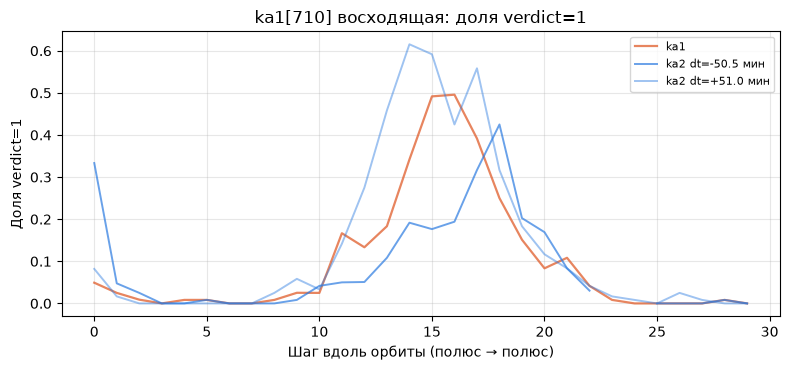

,dt (мин),n шагов,r,ρ,r²,RMSE,MAE
ka2,,,,,,,
1,-50.5,28 из 30,0.663,0.912,0.440,0.115,0.066
2,+51.0,30 из 30,0.932,0.902,0.869,0.087,0.046


In [24]:
from IPython.display import HTML, display

N_CONJ_EXAMPLES = 6
CONJ_EXAMPLE_SEED = 7  # сменить, чтобы взять другой набор

if 'conjugates_ka1' not in globals() or 'df_conj' not in globals():
    raise RuntimeError('сначала выполните ячейку п.10 (conjugates_ka1 / df_conj)')

_rng = np.random.default_rng(CONJ_EXAMPLE_SEED)
_with_mates = np.array([i for i, c in enumerate(conjugates_ka1) if c['ka2']], dtype=int)
if _with_mates.size == 0:
    raise RuntimeError('нет ни одной ka1 с сопряжённым ka2 — сначала п.7 и ячейка conjugates_ka1')
_n = min(N_CONJ_EXAMPLES, int(_with_mates.size))

_asc_i = np.array([i for i in _with_mates if conjugates_ka1[i]['ascending']], dtype=int)
_desc_i = np.array([i for i in _with_mates if not conjugates_ka1[i]['ascending']], dtype=int)


def _take(pool, k):
    if k <= 0 or pool.size == 0:
        return np.array([], dtype=int)
    k = min(int(k), int(pool.size))
    return _rng.choice(pool, size=k, replace=False)


_n_asc = min((_n + 1) // 2, int(_asc_i.size))
_n_desc = min(_n - _n_asc, int(_desc_i.size))
_picked = np.concatenate([_take(_asc_i, _n_asc), _take(_desc_i, _n_desc)])
if _picked.size < _n:
    _rest = np.setdiff1d(_with_mates, _picked, assume_unique=False)
    _picked = np.concatenate([_picked, _take(_rest, _n - int(_picked.size))])
_ex_idx = np.sort(_picked).astype(int).tolist()
print(f'примеры индексов ka1 (из {len(conjugates_ka1)}): {_ex_idx}')
display(df_conj.iloc[_ex_idx])


def _conj_cell_html(p):
    if '_cell_html' in globals():
        return _cell_html(p)
    t0, t1 = p['t'][0], p['t'][-1]
    dt0 = pd.Timestamp(int(t0), unit='s', tz='UTC').strftime('%Y-%m-%d %H:%M:%S')
    dt1 = pd.Timestamp(int(t1), unit='s', tz='UTC').strftime('%H:%M:%S')
    return (f'{dt0} .. {dt1}<br>'
            f'широта {p["lat"][0]:.1f}° → {p["lat"][-1]:.1f}°, '
            f'долгота {p["lon"][0]:.1f}° → {p["lon"][-1]:.1f}°')


def _conj_pair_html(c):
    dir_lab = 'восходящая' if c['ascending'] else 'нисходящая'
    cols = [f'<th>ka1 {dir_lab}</th>'] + [
        f'<th>ka2 #{k + 1} (dt={m["dt_s"]/60:+.1f} мин)</th>' for k, m in enumerate(c['ka2'])
    ]
    cells = [_conj_cell_html(c['ka1'])] + [_conj_cell_html(m['profile']) for m in c['ka2']]
    row = ''.join(f'<td>{x}</td>' for x in cells)
    return ('<table style="border-collapse:collapse;font-size:13px;margin:8px 0" border="1" cellpadding="6">'
            f'<tr>{"".join(cols)}</tr><tr>{row}</tr></table>')


def _fmt(x, spec='{:.3f}'):
    return spec.format(x) if np.isfinite(x) else '—'


def _metrics_table(c):
    rows = []
    for k, m in enumerate(c['ka2'], start=1):
        met = m.get('metrics') or verdict_pair_metrics(c['ka1']['verdict'], m['profile']['verdict'])
        rows.append({
            'ka2': k,
            'dt (мин)': f'{m["dt_s"]/60:+.1f}',
            'n шагов': f'{met["n"]} из {met["n_all"]}',
            'r': _fmt(met['r']),
            'ρ': _fmt(met.get('rho', np.nan)),
            'r²': _fmt(met['r2']),
            'RMSE': _fmt(met['rmse']),
            'MAE': _fmt(met['mae']),
        })
    return pd.DataFrame(rows).set_index('ka2')


for i in _ex_idx:
    c = conjugates_ka1[i]
    dir_lab = 'восходящая' if c['ascending'] else 'нисходящая'
    t1 = pd.Timestamp(int(c['t_eq']), unit='s', tz='UTC')
    print(f'\n--- ka1[{i}] {dir_lab}, экватор {t1:%Y-%m-%d %H:%M:%S} UTC, {len(c["ka2"])} ka2 ---')
    display(HTML(_conj_pair_html(c)))

    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.plot(steps, c['ka1']['verdict'], color='#e05c2a', alpha=0.75, lw=1.6, label='ka1')
    for k, m in enumerate(c['ka2']):
        ax.plot(steps, m['profile']['verdict'], color='#2a7ae0', alpha=0.45 + 0.25 * (k == 0),
                lw=1.4, label=f'ka2 dt={m["dt_s"]/60:+.1f} мин')
    ax.set_title(f'ka1[{i}] {dir_lab}: доля verdict=1')
    ax.set_xlabel('Шаг вдоль орбиты (полюс → полюс)')
    ax.set_ylabel('Доля verdict=1')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    display(_metrics_table(c))
